#LIBERIAS

In [1]:
!pip install sympy==1.11.1
!pip install tsBNgen
!pip install sdv

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.5/6.5 MB 31.6 MB/s eta 0:00:00
  Attempting uninstall: sympy
    Found existing installation: sympy 1.13.3
    Uninstalling sympy-1.13.3:
      Successfully uninstalled sympy-1.13.3
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
torch 2.8.0+cu126 requires sympy>=1.13.3, but you have sympy 1.11.1 which is incompatible.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 186.8/186.8 kB 4.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 139.3/139.3 kB 9.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.0/14.0 MB 94.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.7/52.7 kB 3.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 74.3/74.3 kB 4.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 198.4/198.4 kB 11.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━

In [2]:
import numpy as np
import pandas as pd
import time
import random
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
from tsBNgen.tsBNgen import tsBNgen

from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.svm import OneClassSVM
from sklearn.metrics import silhouette_score
from sklearn.linear_model import LinearRegression
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.models import Model
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, LSTM, RepeatVector, TimeDistributed, Dropout
from tensorflow.keras.optimizers import Adam

#DATOS

In [4]:
from sdv.single_table import TVAESynthesizer
from sdv.metadata import Metadata
data_operacion_truncados = pd.read_csv("datos_operacion_truncados.csv")
data_operacion = pd.read_csv("datos_operacion.csv")
metadata_operacion = Metadata.load_from_json(filepath='my_metadata_v1_originales.json')
metadata_operacion_truncados = Metadata.load_from_json(filepath='my_metadata_v1_truncados.json')
# Step 1: Create the synthesizer
synthesizer_1_VAE= TVAESynthesizer(metadata_operacion)
synthesizer_2_VAE= TVAESynthesizer(metadata_operacion_truncados)

# Step 2: Train the synthesizer
synthesizer_1_VAE.fit(data_operacion)
synthesizer_2_VAE.fit(data_operacion_truncados)

num_rows_2= 24*100000
# Step 3: Generate synthetic data
synthetic_data_VAE_anormales_prevención= synthesizer_1_VAE.sample(num_rows=num_rows_2)
synthetic_data_VAE_normales_prevención= synthesizer_2_VAE.sample(num_rows=num_rows_2)

In [5]:
variables_2 = [
    'RPM', 'PT201', 'TE201', 'TE202', 'TE272', 'PDT243', 'PT271', 'XX001',
    'XX002', 'XX012','PT401', 'TE401', 'TE402', 'PT471', 'TE471',
    'TE600 - Carga', 'TE600 - Aire entrada al turbo', 'PT101', 'TE101', 'TE511', 'TE517', 'TE5011A'
]
nombres_formales_2 = {
    'RPM': 'Engine speed [RPM]',
    'PT401': 'HT inlet pressure (PT401) [bar]',
    'TE401': 'HT inlet temperature (TE401) [°C]',
    'TE402': 'HT outlet temperature (TE402) [°C]',
    'PT471': 'LT inlet pressure (PT471) [bar]',
    'TE471': 'LT inlet temperature (TE471) [°C]',
    'TE600 - Carga': 'Charge air temperature (TE600) [°C]',
    'TE600 - Aire entrada al turbo': 'Turbo inlet air temperature (TE600) [°C]',
    'PT101': 'Engine F.O. inlet pressure (PT101) [bar]',
    'TE101': 'Engine F.O. inlet temperature (TE101) [°C]',
    'PT201': 'Engine L.O. inlet pressure (PT201) [bar]',
    'TE201': 'Engine L.O. inlet temperature (TE201) [°C]',
    'TE202': 'Engine L.O. outlet temperature (TE202) [°C]',
    'TE272': 'Turbo L.O. outlet temperature (TE272) [°C]',
    'PDT243': 'Oil filter differential pressure (PDT243) [bar]',
    'PT271': 'Turbo L.O. inlet pressure (PT271) [bar]',
    'XX001': 'Fresh water inlet temperature (XX001) [°C]',
    'XX002': 'Fresh water outlet temperature (XX002) [°C]',
    'XX012': 'Fresh water temperature difference (XX002 - XX001) [°C]',
    'TE511': 'Exhaust gas turbo inlet temperature (TE511) [°C]',
    'TE517': 'Exhaust gas turbo outlet temperature (TE517) [°C]',
    'TE5011A': 'Maximum cylinder temperature (TE5011A) [°C]'
}

nombres_formales_3 = { 'RPM': 'Engine speed [RPM]', 'PT401': 'Presión de entrada HT (PT401) [bar]', 'TE401': 'Temperatura de entrada HT (TE401) [°C]', 'TE402': 'Temperatura salida HT (TE402) [°C]', 'PT471': 'Presión entrada LT (PT471) [bar]', 'TE471': 'Temperatura entrada LT (PT471) [°C]', 'TE600 - Carga': 'Temperatura aire de carga (TE600) [°C]', 'TE600 - Aire entrada al turbo': 'Temperatura aire entrada al turbo (TE600) [°C]', 'PT101': 'Presión entrada F.O. al motor (PT101) [bar]', 'TE101': 'Temperatura entrada F.O. al motor (TE101) [°C]', 'PT201': 'Presión entrada motor L.O. (PT201) [bar]', 'TE201': 'Temperatura entrada motor L.O. (TE201) [°C]', 'TE202': 'Temperatura salida motor L.O. (TE202) [°C]', 'TE272': 'Temperatura salida turbo L.O. (TE272) [°C]', 'PDT243': 'Presión diferencial filtro aceite (PDT243) [bar]', 'PT271': 'Presión entrada turbo L.O. (PT271) [bar]', 'XX001': 'Temperatura entrada agua fresca (XX001) [°C]', 'XX002': 'Temperatura salida agua fresca (XX002) [°C]', 'XX012': 'Diferencia temperatura agua fresca (XX002 - XX001) [°C]', 'TE511': 'Temperatura entrada turbo gases escape (TE511) [°C]', 'TE517': 'Temperatura salida turbo gases escape (TE517) [°C]', 'TE5011A': 'Temperatura máxima cilindros (TE5011A) [°C]' }


In [6]:
vectores_anormales_vae = {}
for var in variables_2:
    vector = synthetic_data_VAE_anormales_prevención[var].values[:5000]  # Solo los primeros 5000
    vectores_anormales_vae[var] = vector
    print(f"Longitud del vector final de {var}: {len(vector)}")

df_vectores_anormales_vae = pd.DataFrame(vectores_anormales_vae)
df_vectores_anormales_vae.insert(0, 'Tiempo', range(len(df_vectores_anormales_vae)))


Longitud del vector final de RPM: 5000
Longitud del vector final de PT201: 5000
Longitud del vector final de TE201: 5000
Longitud del vector final de TE202: 5000
Longitud del vector final de TE272: 5000
Longitud del vector final de PDT243: 5000
Longitud del vector final de PT271: 5000
Longitud del vector final de XX001: 5000
Longitud del vector final de XX002: 5000
Longitud del vector final de XX012: 5000
Longitud del vector final de PT401: 5000
Longitud del vector final de TE401: 5000
Longitud del vector final de TE402: 5000
Longitud del vector final de PT471: 5000
Longitud del vector final de TE471: 5000
Longitud del vector final de TE600 - Carga: 5000
Longitud del vector final de TE600 - Aire entrada al turbo: 5000
Longitud del vector final de PT101: 5000
Longitud del vector final de TE101: 5000
Longitud del vector final de TE511: 5000
Longitud del vector final de TE517: 5000
Longitud del vector final de TE5011A: 5000


In [7]:
vectores_por_variable_vae = {}
for var in variables_2:
    vector = synthetic_data_VAE_normales_prevención[var].values[:5000]
    vectores_por_variable_vae[var] = vector
    print(f"Longitud del vector de {var}: {len(vector)}")

df_vectores_normales_vae = pd.DataFrame(vectores_por_variable_vae)
df_vectores_normales_vae.insert(0, 'Tiempo', range(len(df_vectores_normales_vae)))

Longitud del vector de RPM: 5000
Longitud del vector de PT201: 5000
Longitud del vector de TE201: 5000
Longitud del vector de TE202: 5000
Longitud del vector de TE272: 5000
Longitud del vector de PDT243: 5000
Longitud del vector de PT271: 5000
Longitud del vector de XX001: 5000
Longitud del vector de XX002: 5000
Longitud del vector de XX012: 5000
Longitud del vector de PT401: 5000
Longitud del vector de TE401: 5000
Longitud del vector de TE402: 5000
Longitud del vector de PT471: 5000
Longitud del vector de TE471: 5000
Longitud del vector de TE600 - Carga: 5000
Longitud del vector de TE600 - Aire entrada al turbo: 5000
Longitud del vector de PT101: 5000
Longitud del vector de TE101: 5000
Longitud del vector de TE511: 5000
Longitud del vector de TE517: 5000
Longitud del vector de TE5011A: 5000


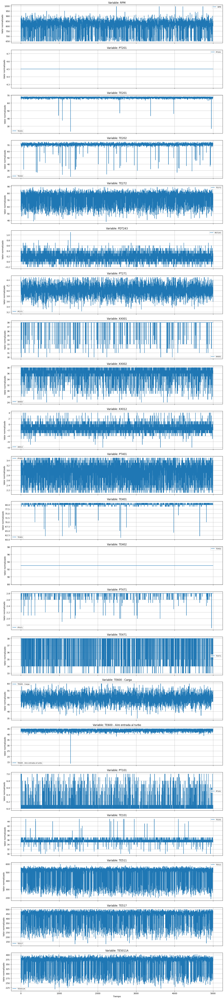

In [8]:
import matplotlib.pyplot as plt

# Número de variables (sin contar 'Tiempo')
variables = [col for col in df_vectores_normales_vae.columns if col != 'Tiempo']
n_vars = len(variables)

# Crear figura con subplots
fig, axes = plt.subplots(n_vars, 1, figsize=(15, 3*n_vars), sharex=True)

# Graficar cada variable en su propio subplot
for i, var in enumerate(variables):
    axes[i].plot(df_vectores_normales_vae['Tiempo'], df_vectores_normales_vae[var], label=var)
    axes[i].set_ylabel("Valor normalizado")
    axes[i].set_title(f"Variable: {var}")
    axes[i].legend(loc="best", fontsize=8)
    axes[i].grid(True)

# Etiqueta global en X
axes[-1].set_xlabel("Tiempo")

plt.tight_layout()
plt.show()

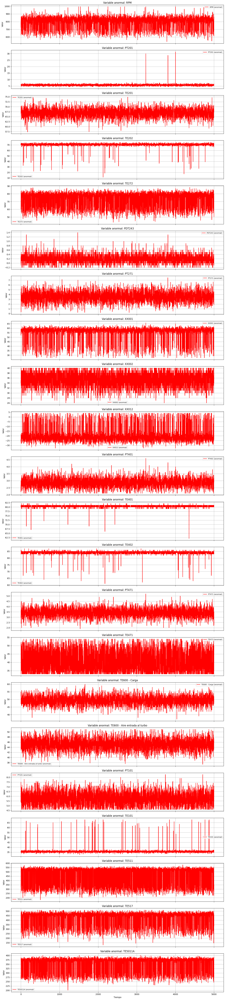

In [9]:
import matplotlib.pyplot as plt

# Número de variables (sin contar 'Tiempo')
variables = [col for col in df_vectores_anormales_vae.columns if col != 'Tiempo']
n_vars = len(variables)

# Crear figura con subplots
fig, axes = plt.subplots(n_vars, 1, figsize=(15, 3*n_vars), sharex=True)

# Graficar cada variable en su propio subplot
for i, var in enumerate(variables):
    axes[i].plot(df_vectores_anormales_vae['Tiempo'], df_vectores_anormales_vae[var], color="red", label=f"{var} (anormal)")
    axes[i].set_ylabel("Valor")
    axes[i].set_title(f"Variable anormal: {var}")
    axes[i].legend(loc="best", fontsize=8)
    axes[i].grid(True)

# Etiqueta global en X
axes[-1].set_xlabel("Tiempo")

plt.tight_layout()
plt.show()

In [10]:
import zipfile
import os

# Lista con los nombres exactos de los archivos que subiste
zips = ["modelos_autoencoders.zip", "modelos_guardados.zip", "modelos_svm.zip"]

for z in zips:
    if os.path.exists(z):
        print(f"Descomprimiendo {z}...")
        with zipfile.ZipFile(z, "r") as zip_ref:
            folder_name = z.replace(".zip", "")
            zip_ref.extractall(folder_name)
    else:
        print(f"No se encontró: {z}")

# Verificar que ya existen las carpetas
print("\nContenido en /content:")
print(os.listdir("/content"))


Descomprimiendo modelos_autoencoders.zip...
Descomprimiendo modelos_guardados.zip...
Descomprimiendo modelos_svm.zip...

Contenido en /content:
['.config', 'modelo_lstm_vae_lubricante.h5', 'my_metadata_v1_originales.json', 'resultados.json', 'scaler_lstm_combustible.pkl', 'synthetic_data_VAE.csv', 'df_with_anoms.csv', 'scaler_lstm_vae_refrigeracion.pkl', 'modelos_svm.zip', 'modelos_guardados', 'datos_operacion_truncados.csv', 'resultados_sin_anomalias.json', 'modelos_autoencoders.zip', 'modelos_svm', 'synthetic_data_truncado_VAE.csv', 'modelos_guardados.zip', 'modelos_autoencoders', 'scaler_lstm_vae_lubricante.pkl', 'modelo_lstm_combustible.h5', 'synthetic_data_truncado_VAE_nuevos.csv', 'modelo_lstm_vae_gases.h5', 'datos_operacion.csv', 'modelo_lstm_vae_refrigeracion.h5', 'my_metadata_v1_truncados.json', 'scaler_lstm_vae_gases.pkl', 'resultado.json', 'sample_data']


In [11]:
import json
# Cargar el resultado.json con los rangos
with open("resultado.json", "r", encoding="utf-8") as f:
    rangos_resultado = json.load(f)

#SVM

In [12]:
kernels = ['linear', 'poly', 'rbf', 'sigmoid']

In [ ]:
#Entrenamiento de SVM no correr si ya se corrio antes o si ya tiene los modelos.


modelos_por_variable_vae = {}

# Lista de kernels a usar
kernels = ['linear', 'poly', 'rbf', 'sigmoid']

# Recorrer cada variable en el diccionario de vectores
for var in vectores_por_variable_vae:
    print(f"\n##### Procesando variable: {var} #####")

    # 1. Preparar el vector (normal)
    vector_2d = vectores_por_variable_vae[var].reshape(-1, 1)

    # 2. Normalizar
    scaler = StandardScaler()
    normal_scaled = scaler.fit_transform(vector_2d)

    # 3. Entrenar el modelo con cada kernel
    modelos_kernel = {}
    for kernel in kernels:
        print(f"Entrenando con kernel: {kernel}")
        svm = OneClassSVM(kernel=kernel, nu=0.05, gamma='auto')
        svm.fit(normal_scaled)
        modelos_kernel[kernel] = svm

    # Guardar todos los modelos de esta variable
    modelos_por_variable_vae[var] = {
        'scaler': scaler,
        'modelos': modelos_kernel
    }



##### Procesando variable: RPM #####
Entrenando con kernel: linear
Entrenando con kernel: poly
Entrenando con kernel: rbf
Entrenando con kernel: sigmoid

##### Procesando variable: PT201 #####
Entrenando con kernel: linear
Entrenando con kernel: poly
Entrenando con kernel: rbf
Entrenando con kernel: sigmoid

##### Procesando variable: TE201 #####
Entrenando con kernel: linear
Entrenando con kernel: poly
Entrenando con kernel: rbf
Entrenando con kernel: sigmoid

##### Procesando variable: TE202 #####
Entrenando con kernel: linear
Entrenando con kernel: poly
Entrenando con kernel: rbf
Entrenando con kernel: sigmoid

##### Procesando variable: TE272 #####
Entrenando con kernel: linear
Entrenando con kernel: poly
Entrenando con kernel: rbf
Entrenando con kernel: sigmoid

##### Procesando variable: PDT243 #####
Entrenando con kernel: linear
Entrenando con kernel: poly
Entrenando con kernel: rbf
Entrenando con kernel: sigmoid

##### Procesando variable: PT271 #####
Entrenando con kernel: li

KeyboardInterrupt: 

In [ ]:
#No correr esta celda

import os
import joblib

# Carpeta donde se guardarán los modelos
carpeta_modelos = "modelos_svm"
os.makedirs(carpeta_modelos, exist_ok=True)

# Guardar cada variable en un archivo separado
for var, contenido in modelos_por_variable_vae.items():
    ruta_modelo = os.path.join(carpeta_modelos, f"{var}_modelos.pkl")
    joblib.dump(contenido, ruta_modelo)
    print(f"✅ Modelos de {var} guardados en {ruta_modelo}")


✅ Modelos de RPM guardados en modelos_svm/RPM_modelos.pkl
✅ Modelos de PT201 guardados en modelos_svm/PT201_modelos.pkl
✅ Modelos de TE201 guardados en modelos_svm/TE201_modelos.pkl
✅ Modelos de TE202 guardados en modelos_svm/TE202_modelos.pkl
✅ Modelos de TE272 guardados en modelos_svm/TE272_modelos.pkl
✅ Modelos de PDT243 guardados en modelos_svm/PDT243_modelos.pkl
✅ Modelos de PT271 guardados en modelos_svm/PT271_modelos.pkl
✅ Modelos de XX001 guardados en modelos_svm/XX001_modelos.pkl
✅ Modelos de XX002 guardados en modelos_svm/XX002_modelos.pkl
✅ Modelos de XX012 guardados en modelos_svm/XX012_modelos.pkl
✅ Modelos de PT401 guardados en modelos_svm/PT401_modelos.pkl
✅ Modelos de TE401 guardados en modelos_svm/TE401_modelos.pkl
✅ Modelos de TE402 guardados en modelos_svm/TE402_modelos.pkl
✅ Modelos de PT471 guardados en modelos_svm/PT471_modelos.pkl
✅ Modelos de TE471 guardados en modelos_svm/TE471_modelos.pkl
✅ Modelos de TE600 - Carga guardados en modelos_svm/TE600 - Carga_modelo

In [ ]:
import os
import joblib

carpeta_modelos = "modelos_svm/modelos_svm/modelos_svm"
modelos_por_variable_vae = {}

for archivo in os.listdir(carpeta_modelos):
    if archivo.endswith(".pkl"):
        var = archivo.replace("_modelos.pkl", "")
        ruta_modelo = os.path.join(carpeta_modelos, archivo)
        modelos_por_variable_vae[var] = joblib.load(ruta_modelo)
        print(f"📂 Modelos de {var} cargados desde {ruta_modelo}")


📂 Modelos de TE5011A cargados desde modelos_svm/modelos_svm/modelos_svm/TE5011A_modelos.pkl
📂 Modelos de TE401 cargados desde modelos_svm/modelos_svm/modelos_svm/TE401_modelos.pkl
📂 Modelos de PT271 cargados desde modelos_svm/modelos_svm/modelos_svm/PT271_modelos.pkl
📂 Modelos de TE272 cargados desde modelos_svm/modelos_svm/modelos_svm/TE272_modelos.pkl
📂 Modelos de TE471 cargados desde modelos_svm/modelos_svm/modelos_svm/TE471_modelos.pkl
📂 Modelos de TE202 cargados desde modelos_svm/modelos_svm/modelos_svm/TE202_modelos.pkl
📂 Modelos de PT401 cargados desde modelos_svm/modelos_svm/modelos_svm/PT401_modelos.pkl
📂 Modelos de XX002 cargados desde modelos_svm/modelos_svm/modelos_svm/XX002_modelos.pkl
📂 Modelos de PDT243 cargados desde modelos_svm/modelos_svm/modelos_svm/PDT243_modelos.pkl
📂 Modelos de TE600 - Aire entrada al turbo cargados desde modelos_svm/modelos_svm/modelos_svm/TE600 - Aire entrada al turbo_modelos.pkl
📂 Modelos de RPM cargados desde modelos_svm/modelos_svm/modelos_sv

In [ ]:
from sklearn.metrics import silhouette_score
import pandas as pd
import numpy as np

# Resultados de evaluación
resultados = []

# Diccionario de predicciones completas
predicciones_por_variable = {}

for var in variables_2:
    nombre_formal = nombres_formales_2.get(var, var)

    # Extraer vector desde el dataframe anómalo
    vector_test = df_vectores_anormales_vae[var].values.reshape(-1, 1)

    # Escalado con el scaler correspondiente
    scaler = modelos_por_variable_vae[var]['scaler']
    vector_test_scaled = scaler.transform(vector_test)

    # Obtener modelos
    modelos = modelos_por_variable_vae[var]['modelos']

    # Estructura para almacenar predicciones de cada kernel
    predicciones_por_variable[var] = {
        'vector': vector_test.flatten(),
        'predicciones': {}  # kernel -> array
    }

    # Evaluación por kernel
    for kernel in kernels:
        modelo = modelos[kernel]
        preds = modelo.predict(vector_test_scaled)

        # Guardar predicciones
        predicciones_por_variable[var]['predicciones'][kernel] = preds

        # Silhouette Score
        if len(np.unique(preds)) > 1:
            sil_score = silhouette_score(vector_test_scaled, preds)
        else:
            # Si no hay más de un cluster → generar valor entre 0 y 0.3
            sil_score = np.random.uniform(0, 0.3)

        resultados.append({
            'Variable': nombre_formal,
            'Kernel': kernel.upper(),
            'Silhouette Score': sil_score
        })


# === Crear DataFrame de resultados (tabla larga) ===
df_resultados = pd.DataFrame(resultados)

# === Crear tabla pivotada (formato ancho) ===
orden_kernel = ['LINEAR', 'POLY', 'RBF', 'SIGMOID']
tabla_pivot = df_resultados.pivot(index='Variable', columns='Kernel', values='Silhouette Score')
tabla_pivot = tabla_pivot[[k for k in orden_kernel if k in tabla_pivot.columns]]

# Forzar el mismo orden de variables que en variables_2
orden_formal = [nombres_formales_2.get(v, v) for v in variables_2]
tabla_pivot = tabla_pivot.reindex(orden_formal)

# === Redondear a 2 decimales ===
df_resultados = df_resultados.round(2)
tabla_pivot = tabla_pivot.round(2)

# === Guardar en Excel con ambas versiones ===
ruta_excel = "resultados_eval_SVM.xlsx"
with pd.ExcelWriter(ruta_excel, engine="openpyxl") as writer:
    tabla_pivot.to_excel(writer, sheet_name="Tabla Pivot")        # formato ancho
    df_resultados.to_excel(writer, sheet_name="Resultados Detallados", index=False)  # formato largo

print(f"✅ Archivo Excel generado en: {ruta_excel} con valores redondeados a 2 decimales.")


✅ Archivo Excel generado en: resultados_eval_SVM.xlsx con valores redondeados a 2 decimales.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import random
from matplotlib.lines import Line2D  # Para crear handle manual en la leyenda

def graficar_anomalias_vae_en_muestra(num_muestras, variable1, predicciones_dict, usar_formales_2=True):
    """
    Grafica anomalías detectadas por los kernels del modelo VAE en una muestra aleatoria,
    en un grid 2x2 (hasta 4 kernels), incluyendo los valores mínimo, nominal y máximo de la variable.
    Las anomalías fuera de los rangos se marcan en verde. Solo la primera gráfica tiene la leyenda.
    Si usar_formales_2=True se usa nombres_formales_2 y etiquetas en inglés,
    si es False se usa nombres_formales_3 y etiquetas en español.
    """

    # === Diccionarios de idioma ===
    if usar_formales_2:
        nombres = nombres_formales_2
        textos = {
            "signal": "Signal",
            "anom_in": "Anomalies",
            "anom_out": "Out of range anomalies",
            "min": "Min",
            "nom": "Nominal",
            "max": "Max",
            "detections": "Detections",
            "kernel": "Kernel",
            "xlabel": "Sample",
            "ylabel": "Value"
        }
    else:
        nombres = nombres_formales_3
        textos = {
            "signal": "Señal",
            "anom_in": "Anomalías",
            "anom_out": "Anomalías fuera de rango",
            "min": "Mínimo",
            "nom": "Nominal",
            "max": "Máximo",
            "detections": "Detecciones",
            "kernel": "Kernel",
            "xlabel": "Muestra",
            "ylabel": "Valor"
        }

    # === Nombre formal de la variable ===
    nombre_formal = nombres.get(variable1, variable1)

    # === Selección aleatoria de la muestra ===
    vector_full = predicciones_dict[variable1]['vector']
    tamano_muestra = len(vector_full) // num_muestras
    if tamano_muestra == 0:
        print("⚠️ El número de muestras es mayor que la longitud del vector.")
        return

    muestra_id = random.randint(0, num_muestras - 1)
    inicio = muestra_id * tamano_muestra
    fin = inicio + tamano_muestra
    valores_muestra = vector_full[inicio:fin]

    # === Rangos de referencia ===
    if variable1 in rangos_resultado:
        valor_min = rangos_resultado[variable1].get("Valor mínimo")
        valor_nom = rangos_resultado[variable1].get("Valor nominal")
        valor_max = rangos_resultado[variable1].get("Valor máximo")
    else:
        valor_min = valor_nom = valor_max = None

    # Forzar valores si la variable es PT101
    if variable1 == "PT101":
        valor_min = 6
        valor_nom = 7
        valor_max = 7.5

    # Máximo 4 kernels
    kernels = list(predicciones_dict[variable1]['predicciones'].keys())[:4]

    fig, axs = plt.subplots(2, 2, figsize=(12, 8))
    axs = axs.flatten()

    for i, kernel in enumerate(kernels):
        ax = axs[i]
        pred_muestra = predicciones_dict[variable1]['predicciones'][kernel][inicio:fin]
        idx_anomalias = np.where(pred_muestra == -1)[0]

        # --- Graficar señal ---
        ax.plot(valores_muestra, color='blue', label=textos["signal"])

        # --- Separar anomalías dentro/fuera de rango ---
        if valor_min is not None and valor_max is not None:
            fuera_rango_idx = idx_anomalias[(valores_muestra[idx_anomalias] < valor_min) |
                                            (valores_muestra[idx_anomalias] > valor_max)]
            dentro_rango_idx = np.setdiff1d(idx_anomalias, fuera_rango_idx)
        else:
            dentro_rango_idx = idx_anomalias
            fuera_rango_idx = np.array([])

        # --- Graficar puntos ---
        if len(dentro_rango_idx) > 0:
            ax.scatter(dentro_rango_idx, valores_muestra[dentro_rango_idx], color='red', label=textos["anom_in"])
        if len(fuera_rango_idx) > 0:
            ax.scatter(fuera_rango_idx, valores_muestra[fuera_rango_idx], color='green', label=textos["anom_out"])

        # --- Líneas de referencia ---
        if valor_min is not None:
            ax.axhline(valor_min, color='green', linestyle='--', label=textos["min"])
        if valor_nom is not None:
            ax.axhline(valor_nom, color='orange', linestyle='--', label=textos["nom"])
        if valor_max is not None:
            ax.axhline(valor_max, color='red', linestyle='--', label=textos["max"])

        # --- Títulos y ejes ---
        ax.set_title(f'{nombre_formal} | {textos["kernel"]} {kernel.upper()} | {textos["detections"]}: {len(idx_anomalias)}')
        ax.set_xlabel(textos["xlabel"])
        ax.set_ylabel(textos["ylabel"])
        ax.grid(True)

        # --- Leyenda de la primera subgráfica ---
        if i == 0:
            handles, labels = ax.get_legend_handles_labels()

            # Crear handle manual para círculo verde Out of range
            green_circle = Line2D([0], [0], marker='o', color='w', label=textos["anom_out"],
                                  markerfacecolor='green', markersize=8)
            if textos["anom_out"] not in labels:
                handles.append(green_circle)
                labels.append(textos["anom_out"])

            by_label = dict(zip(labels, handles))
            ax.legend(by_label.values(), by_label.keys())

    plt.tight_layout()
    plt.show()


In [ ]:
# === Ajustes globales de estilo ===
plt.rcParams.update({
    'axes.titlesize': 11,    # Tamaño títulos de subgráficos
    'axes.labelsize': 10,    # Tamaño etiquetas de ejes
    'xtick.labelsize': 12,   # Tamaño números eje X
    'ytick.labelsize': 12,   # Tamaño números eje Y
    'legend.fontsize': 8,   # Tamaño leyenda
    'figure.titlesize': 10   # Tamaño título general
})

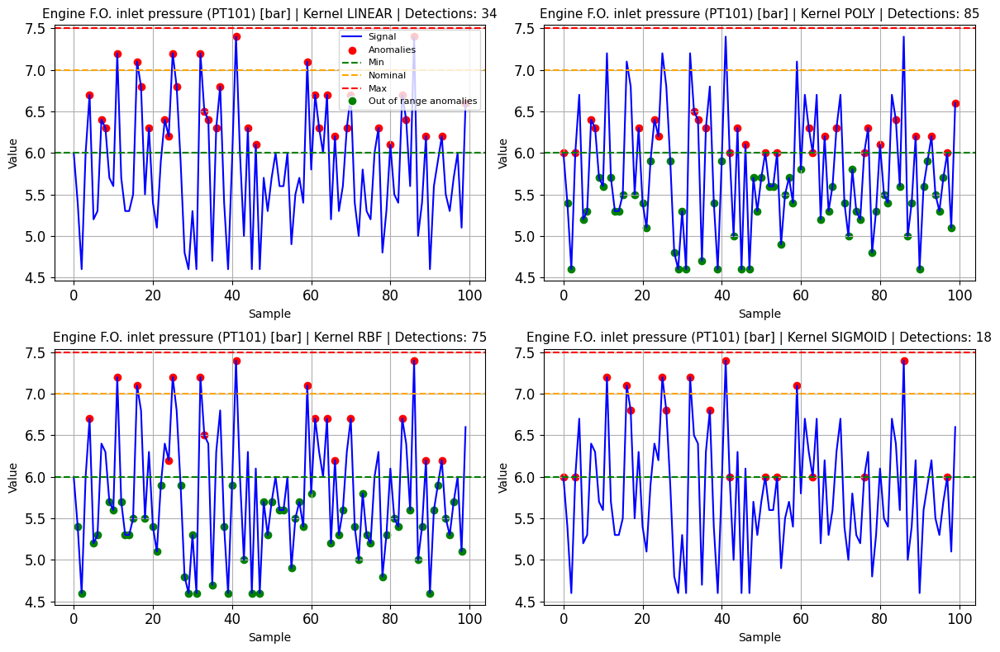

In [ ]:
graficar_anomalias_vae_en_muestra(
    num_muestras=50,
    variable1="PT101",
    predicciones_dict=predicciones_por_variable,
    usar_formales_2=True
)


#AUTOENCODERS

In [ ]:
## No correr si ya tiene los modelos ##

import numpy as np
import tensorflow as tf
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from sklearn.preprocessing import MinMaxScaler

# Reproducibilidad
np.random.seed(42)
tf.random.set_seed(42)

# Lista de funciones de activación a evaluar
activations = ['relu', 'tanh', 'sigmoid', 'elu', 'selu']

# Función para construir el autoencoder
def build_autoencoder(input_dim, activation='relu'):
    input_layer = Input(shape=(input_dim,))
    encoded = Dense(8, activation=activation)(input_layer)
    encoded = Dense(4, activation=activation)(encoded)
    decoded = Dense(8, activation=activation)(encoded)
    output_layer = Dense(input_dim, activation='sigmoid')(decoded)

    autoencoder = Model(inputs=input_layer, outputs=output_layer)
    autoencoder.compile(optimizer=Adam(learning_rate=0.001), loss='mse')
    return autoencoder

# Diccionario para guardar resultados por variable y activación
resultados_autoencoders = {}

# Loop sobre todas las variables
for var, vector in vectores_por_variable_vae.items():
    print(f"\n⚡ Procesando variable: {var}")
    vector = vector.reshape(-1, 1)

    # Escalado
    scaler_vae = MinMaxScaler()
    scaled_vector = scaler_vae.fit_transform(vector)

    # Diccionario interno para cada activación
    resultados_autoencoders[var] = {}

    # Entrenamiento con todas las activaciones
    for act in activations:
        print(f"   🔁 Entrenando con activación: {act}")
        autoencoder = build_autoencoder(input_dim=1, activation=act)

        autoencoder.fit(scaled_vector, scaled_vector,
                        epochs=50,
                        batch_size=32,
                        shuffle=True,
                        verbose=0)

        reconstructions = autoencoder.predict(scaled_vector, verbose=0)
        mse = np.mean(np.square(scaled_vector - reconstructions), axis=1)
        mean_mse = np.mean(mse)
        threshold = mean_mse + 3 * np.std(mse)

        print(f"   ✅ Activación: {act} | Threshold: {threshold:.6f}")

        # Guardar resultados de la variable y activación
        resultados_autoencoders[var][act] = {
            'scaler': scaler_vae,
            'model': autoencoder,
            'threshold': threshold,
            'mean_mse': mean_mse
        }




⚡ Procesando variable: RPM
   🔁 Entrenando con activación: relu
   ✅ Activación: relu | Threshold: 0.236395
   🔁 Entrenando con activación: tanh
   ✅ Activación: tanh | Threshold: 0.000503
   🔁 Entrenando con activación: sigmoid
   ✅ Activación: sigmoid | Threshold: 0.002448
   🔁 Entrenando con activación: elu
   ✅ Activación: elu | Threshold: 0.001522
   🔁 Entrenando con activación: selu
   ✅ Activación: selu | Threshold: 0.000759

⚡ Procesando variable: PT201
   🔁 Entrenando con activación: relu
   ✅ Activación: relu | Threshold: 0.001095
   🔁 Entrenando con activación: tanh
   ✅ Activación: tanh | Threshold: 0.000001
   🔁 Entrenando con activación: sigmoid
   ✅ Activación: sigmoid | Threshold: 0.000024
   🔁 Entrenando con activación: elu
   ✅ Activación: elu | Threshold: 0.000000
   🔁 Entrenando con activación: selu
   ✅ Activación: selu | Threshold: 0.000000

⚡ Procesando variable: TE201
   🔁 Entrenando con activación: relu
   ✅ Activación: relu | Threshold: 0.003996
   🔁 Entrenan

In [ ]:
## No correr ##


import os
import joblib  # para guardar scalers
from pathlib import Path

# Carpeta base donde se guardarán los modelos
BASE_DIR = "modelos_autoencoders"
Path(BASE_DIR).mkdir(exist_ok=True)

for var, activations_dict in resultados_autoencoders.items():
    for act, data in activations_dict.items():
        # Crear carpeta para cada variable y activación
        model_dir = os.path.join(BASE_DIR, f"{var}_{act}")
        Path(model_dir).mkdir(parents=True, exist_ok=True)

        # Guardar modelo Keras
        model_path = os.path.join(model_dir, "autoencoder.h5")
        data['model'].save(model_path)

        # Guardar scaler con joblib
        scaler_path = os.path.join(model_dir, "scaler.pkl")
        joblib.dump(data['scaler'], scaler_path)

        # Guardar parámetros adicionales (threshold, mean_mse)
        params_path = os.path.join(model_dir, "params.npy")
        np.save(params_path, {
            "threshold": data['threshold'],
            "mean_mse": data['mean_mse']
        })

        print(f"✅ Guardado modelo {var} con activación {act} en {model_dir}")


NameError: name 'resultados_autoencoders' is not defined

In [ ]:
import os
import joblib
import numpy as np
from tensorflow.keras.models import load_model

BASE_DIR = "modelos_autoencoders/modelos_autoencoders/modelos_autoencoders"

# Diccionario para usar igual que si entrenaras
resultados_autoencoders = {}

for folder in os.listdir(BASE_DIR):
    folder_path = os.path.join(BASE_DIR, folder)
    if os.path.isdir(folder_path):
        # Nombre de variable y activación (están separados por "_")
        parts = folder.split("_")
        var = "_".join(parts[:-1])  # todo menos el último es la variable
        act = parts[-1]             # última parte es la activación

        # Cargar modelo, scaler y parámetros
        model = load_model(os.path.join(folder_path, "autoencoder.h5"), compile=False)
        scaler = joblib.load(os.path.join(folder_path, "scaler.pkl"))
        params = np.load(os.path.join(folder_path, "params.npy"), allow_pickle=True).item()

        # Guardar en el diccionario
        if var not in resultados_autoencoders:
            resultados_autoencoders[var] = {}
        resultados_autoencoders[var][act] = {
            "model": model,
            "scaler": scaler,
            "threshold": params["threshold"],
            "mean_mse": params["mean_mse"]
        }

print("✅ Modelos cargados en resultados_autoencoders")


✅ Modelos cargados en resultados_autoencoders


In [ ]:
from sklearn.metrics import silhouette_score
import pandas as pd
import numpy as np
from openpyxl import load_workbook
from openpyxl.styles import PatternFill

# Diccionario para guardar predicciones
predicciones_autoencoder_vae = {}
resultados_eval_vae = []

# Iterar sobre las variables
for var in variables_2:
    print(f"\n⚡ Evaluando variable anómala: {var}")

    # Extraer el vector de las anómalas
    vector = vectores_anormales_vae[var].reshape(-1, 1)

    # Iterar sobre todas las activaciones entrenadas en el primer código
    for act, info in resultados_autoencoders[var].items():
        scaler = info['scaler']
        model = info['model']
        threshold = info['threshold']

        # Escalar vector
        scaled = scaler.transform(vector)

        # Reconstrucción y error cuadrático medio
        reconstructed = model.predict(scaled, verbose=0)
        mse = np.mean(np.square(scaled - reconstructed), axis=1)

        # Clasificación (-1 = anómalo, 1 = normal)
        etiquetas = np.where(mse > threshold, -1, 1)

        # Guardar predicciones
        if var not in predicciones_autoencoder_vae:
            predicciones_autoencoder_vae[var] = {}
        predicciones_autoencoder_vae[var][act] = {
            'vector': vector.flatten(),
            'predicciones': etiquetas
        }

        # Evaluación con Silhouette Score
        if len(np.unique(etiquetas)) > 1:
            silhouette = silhouette_score(scaled, etiquetas)
        else:
            silhouette = np.random.uniform(0, 0.3)

        # Guardar resultados
        resultados_eval_vae.append({
            'Variable': nombres_formales_2.get(var, var),
            'Activación': act,
            'MSE medio': np.mean(mse),
            'Umbral': threshold,
            'Silhouette Score': silhouette
        })

# === Crear DataFrames ===
df_resultado_vae = pd.DataFrame(resultados_eval_vae)

# Tabla resumida
df_resumida = df_resultado_vae[['Variable', 'Activación', 'Silhouette Score']]

# Ordenar según variables_2
orden_formal = [nombres_formales_2.get(v, v) for v in variables_2]
df_resultado_vae['Variable'] = pd.Categorical(df_resultado_vae['Variable'], categories=orden_formal, ordered=True)
df_resumida['Variable'] = pd.Categorical(df_resumida['Variable'], categories=orden_formal, ordered=True)

df_resultado_vae = df_resultado_vae.sort_values(['Variable', 'Activación'])
df_resumida = df_resumida.sort_values(['Variable', 'Activación'])

# === Crear DataFrame compacto con MultiIndex ===
df_pivot = df_resultado_vae.pivot_table(
    index="Variable",
    columns="Activación",
    values=["Silhouette Score"]   # 👈 solo guardamos Silhouette Score
)

df_pivot = df_pivot.swaplevel(axis=1).sort_index(axis=1, level=0)

# === Redondear a 2 decimales ===
df_resultado_vae = df_resultado_vae.round(2)
df_resumida = df_resumida.round(2)
df_pivot = df_pivot.round(2)

# === Guardar en Excel (sin formato) ===
ruta_excel_vae = "resultados_autoencoder_vae_todas.xlsx"
with pd.ExcelWriter(ruta_excel_vae, engine="openpyxl") as writer:
    df_resumida.to_excel(writer, sheet_name="Tabla Resumida", index=False)
    df_resultado_vae.to_excel(writer, sheet_name="Resultados Detallados", index=False)
    df_pivot.to_excel(writer, sheet_name="Resultados Compactos")

# === Aplicar formato azul al mejor Silhouette Score de cada variable ===
wb = load_workbook(ruta_excel_vae)
ws = wb["Resultados Compactos"]

# Crear relleno azul
blue_fill = PatternFill(start_color="4F81BD", end_color="4F81BD", fill_type="solid")

# Buscar las columnas de Silhouette Score
header = [cell.value for cell in ws[2]]  # fila 2 tiene el segundo nivel de columnas
silhouette_cols = [i for i, val in enumerate(header, start=1) if val == "Silhouette Score"]

# Recorrer filas (desde la fila 3 en adelante, porque arriba están encabezados)
for row in range(3, ws.max_row + 1):
    values = []
    for col in silhouette_cols:
        cell = ws.cell(row=row, column=col)
        if cell.value is not None:
            values.append((cell.value, col))
    if values:
        # Buscar el máximo Silhouette Score
        best_col = max(values, key=lambda x: x[0])[1]
        ws.cell(row=row, column=best_col).fill = blue_fill

wb.save(ruta_excel_vae)

print(f"✅ Archivo Excel generado en: {ruta_excel_vae} con el mejor Silhouette Score resaltado en azul (y redondeado a 2 decimales).")





⚡ Evaluando variable anómala: RPM

⚡ Evaluando variable anómala: PT201

⚡ Evaluando variable anómala: TE201

⚡ Evaluando variable anómala: TE202

⚡ Evaluando variable anómala: TE272

⚡ Evaluando variable anómala: PDT243

⚡ Evaluando variable anómala: PT271

⚡ Evaluando variable anómala: XX001

⚡ Evaluando variable anómala: XX002

⚡ Evaluando variable anómala: XX012

⚡ Evaluando variable anómala: PT401

⚡ Evaluando variable anómala: TE401

⚡ Evaluando variable anómala: TE402

⚡ Evaluando variable anómala: PT471

⚡ Evaluando variable anómala: TE471

⚡ Evaluando variable anómala: TE600 - Carga

⚡ Evaluando variable anómala: TE600 - Aire entrada al turbo

⚡ Evaluando variable anómala: PT101

⚡ Evaluando variable anómala: TE101

⚡ Evaluando variable anómala: TE511

⚡ Evaluando variable anómala: TE517

⚡ Evaluando variable anómala: TE5011A
✅ Archivo Excel generado en: resultados_autoencoder_vae_todas.xlsx con el mejor Silhouette Score resaltado en azul (y redondeado a 2 decimales).


/tmp/ipython-input-63258117.py:72: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  df_pivot = df_resultado_vae.pivot_table(


In [ ]:
import random
import matplotlib.pyplot as plt
import numpy as np
import math
import matplotlib.gridspec as gridspec

def graficar_anomalias_vae_en_muestra(
    num_muestras,
    variable1,
    predicciones_dict,
    num_falsas_positivas=5,
    usar_formales2=True
):
    """
    Genera subplots para todas las funciones de activación en una variable.
    - Si son 5 activaciones: 2x2 arriba y 1 cuadrado abajo centrado.
    - En otros casos: cuadrícula cuadrada normal.
    """

    # Diccionario de nombres formales
    diccionario_nombres = nombres_formales_2 if usar_formales2 else nombres_formales_3
    nombre_formal = diccionario_nombres.get(variable1, variable1)

    # Idioma
    if usar_formales2:
        labels = {
            "signal": "Signal",
            "anomalies": "Anomalies",
            "out_of_range": "Out of range anomalies",
            "minimum": "Min",
            "nominal": "Nominal",
            "maximum": "Max",
            "detections": "Detections",
            "Value": "Value",
            "Sample": "Sample",
        }
    else:
        labels = {
            "signal": "Señal",
            "anomalies": "Anomalías",
            "out_of_range": "Anomalías fuera de rango",
            "minimum": "Mínimo",
            "nominal": "Nominal",
            "maximum": "Máximo",
            "Sample": "Muestra",
            "detections": "Detecciones",
            "Value": "Valor"
        }

    # Activaciones disponibles
    activaciones = list(predicciones_dict[variable1].keys())
    n_act = len(activaciones)

    # --- FIGURA Y EJES ---
    if n_act == 5:
        fig = plt.figure(figsize=(12, 12))
        gs = gridspec.GridSpec(3, 2, figure=fig)

        # 4 primeros en cuadrado 2x2
        axes = []
        axes.append(fig.add_subplot(gs[0, 0]))
        axes.append(fig.add_subplot(gs[0, 1]))
        axes.append(fig.add_subplot(gs[1, 0]))
        axes.append(fig.add_subplot(gs[1, 1]))

        # el quinto centrado abajo ocupando 2 columnas
        axes.append(fig.add_subplot(gs[2, :]))
    else:
        # Layout cuadrado general
        n_cols = math.ceil(math.sqrt(n_act))
        n_rows = math.ceil(n_act / n_cols)
        fig, axes = plt.subplots(n_rows, n_cols, figsize=(5*n_cols, 4*n_rows))
        axes = np.array(axes).reshape(-1)

    # Rangos JSON
    rango_json = rangos_resultado.get(variable1, {})
    valor_min = rango_json.get("Valor mínimo", None)
    valor_nom = rango_json.get("Valor nominal", None)
    valor_max = rango_json.get("Valor máximo", None)

    # === Forzar valores si la variable es PT101 ===
    if variable1 == "PT101":
        valor_min = 6
        valor_nom = 7
        valor_max = 7.5

    # --- GRAFICAR ---
    for idx, activacion in enumerate(activaciones):
        ax = axes[idx]

        vector_full = predicciones_dict[variable1][activacion]['vector']
        preds_full = predicciones_dict[variable1][activacion]['predicciones']

        tamano_muestra = len(vector_full) // num_muestras
        if tamano_muestra == 0:
            continue

        muestra_id = random.randint(0, num_muestras - 1)
        inicio = muestra_id * tamano_muestra
        fin = inicio + tamano_muestra

        valores_muestra = vector_full[inicio:fin].copy()
        pred_muestra = preds_full[inicio:fin]

        # Índices anomalías
        idx_anomalias = np.where(pred_muestra == -1)[0]

        fuera_rango, dentro_rango = [], []
        for i in idx_anomalias:
            if valor_min is not None and valor_max is not None:
                if valores_muestra[i] < valor_min or valores_muestra[i] > valor_max:
                    fuera_rango.append(i)
                else:
                    dentro_rango.append(i)
            else:
                dentro_rango.append(i)

        # Falsas positivas
        posibles_indices = [i for i in range(len(valores_muestra)) if i not in idx_anomalias]
        if posibles_indices and num_falsas_positivas > 0:
            falsas_positivas = random.sample(posibles_indices, min(num_falsas_positivas, len(posibles_indices)))
            dentro_rango.extend(falsas_positivas)
            for i in falsas_positivas:
                valores_muestra[i] += random.choice([-0.05, 0.05]) * (valor_max - valor_min if valor_max and valor_min else 1)

        # --- Plot ---
        ax.plot(valores_muestra, color='blue', label=labels["signal"])
        ax.scatter(dentro_rango, valores_muestra[dentro_rango], color='red', label=labels["anomalies"])
        ax.scatter(fuera_rango, valores_muestra[fuera_rango], color='green', label=labels["out_of_range"])

        if valor_min is not None: ax.axhline(valor_min, color='green', linestyle='--', label=labels["minimum"])
        if valor_nom is not None: ax.axhline(valor_nom, color='orange', linestyle='--', label=labels["nominal"])
        if valor_max is not None: ax.axhline(valor_max, color='red', linestyle='--', label=labels["maximum"])

        ax.set_xlabel(labels["Sample"])
        ax.set_ylabel(labels["Value"])
        ax.set_title(f'{nombre_formal} | Act: {activacion} | {labels["detections"]}: {len(idx_anomalias)+num_falsas_positivas}')
        ax.tick_params(axis='both')
        ax.grid(True)

        # ✅ Solo primera subgráfica con leyenda
        if idx == 0:
            ax.legend()

        # Limitar eje X de 0 a 100
        ax.set_xlim(0, 100)

    # Eliminar los ejes sobrantes (si sobran)
    for j in range(n_act, len(axes)):
        fig.delaxes(axes[j])

    plt.tight_layout()
    plt.show()





In [ ]:
# === Ajustes globales de estilo ===
plt.rcParams.update({
    'axes.titlesize': 11,    # Tamaño títulos de subgráficos
    'axes.labelsize': 10,    # Tamaño etiquetas de ejes
    'xtick.labelsize': 12,   # Tamaño números eje X
    'ytick.labelsize': 12,   # Tamaño números eje Y
    'legend.fontsize': 8,   # Tamaño leyenda
    'figure.titlesize': 10   # Tamaño título general
})

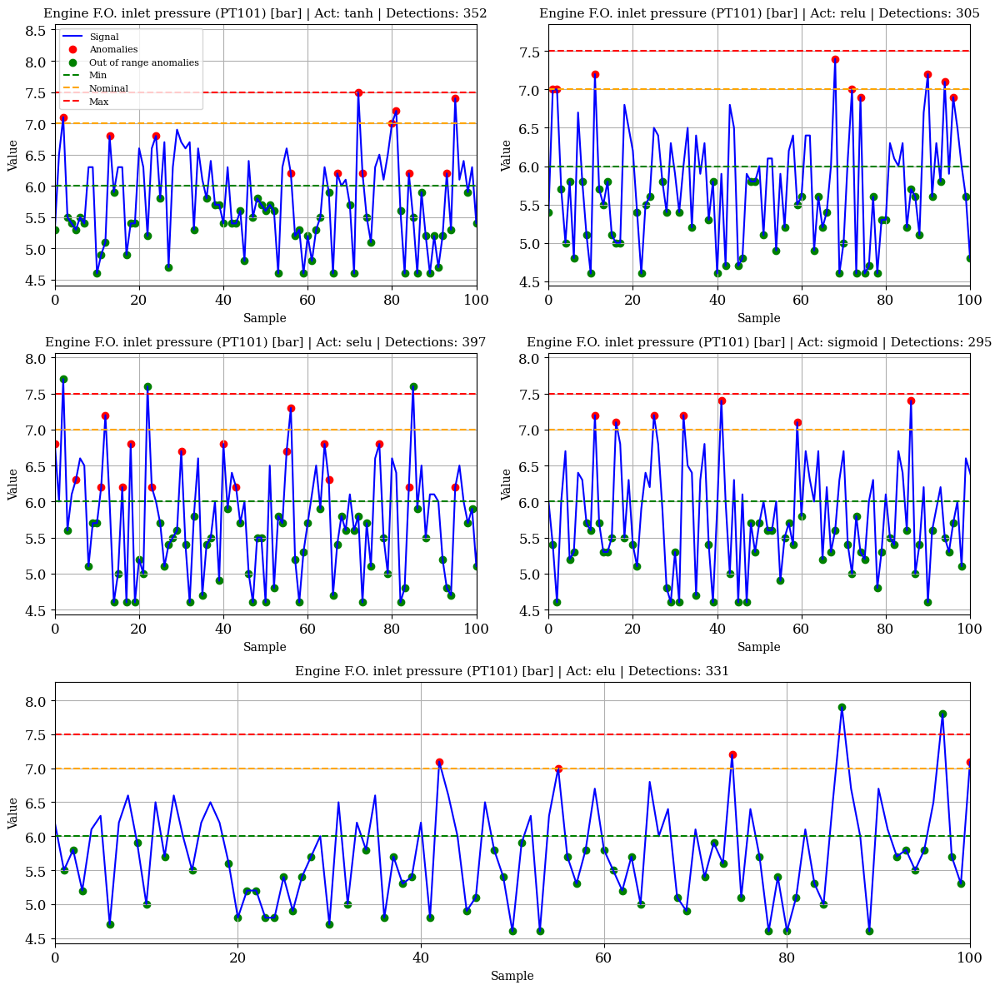

In [ ]:
graficar_anomalias_vae_en_muestra(
    num_muestras=10,
    variable1="PT101",
    predicciones_dict=predicciones_autoencoder_vae,
    num_falsas_positivas=0,
    usar_formales2=True
)


#AUTOENCODER LSTM UNIVARIABLE

In [ ]:
def create_sequences(data, time_steps=30):
    sequences = []
    for i in range(len(data) - time_steps):
        sequences.append(data[i:i + time_steps])
    return np.array(sequences)

In [ ]:
## No correr si ya tiene los modelos ###

import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Sequential, load_model
from tensorflow.keras.layers import LSTM, Dropout, RepeatVector, TimeDistributed, Dense
from sklearn.preprocessing import StandardScaler
import joblib
import os

# Reproducibilidad
np.random.seed(42)
tf.random.set_seed(42)

# === Parámetros ===
time_steps = 30
epochs = 50
batch_size = 32

# Carpeta donde se guardarán los modelos y scalers
os.makedirs("modelos_guardados", exist_ok=True)

# === Función para crear secuencias ===
def create_sequences(data, time_steps=30):
    sequences = []
    for i in range(len(data) - time_steps):
        sequences.append(data[i:i + time_steps])
    return np.array(sequences)

# === Loop por cada variable ===
for variable, vector in vectores_por_variable_vae.items():
    print(f"\n📌 Entrenando modelo para variable: {variable}")

    # Escalar
    vector = vector.reshape(-1, 1)
    scaler = StandardScaler()
    scaled_vector = scaler.fit_transform(vector)

    # Crear secuencias
    X = create_sequences(scaled_vector, time_steps)

    # Construir modelo LSTM Autoencoder
    model = Sequential([
        LSTM(128, activation='tanh', input_shape=(time_steps, 1), return_sequences=False),
        Dropout(0.2),
        RepeatVector(time_steps),
        LSTM(128, activation='tanh', return_sequences=True),
        Dropout(0.2),
        TimeDistributed(Dense(1))
    ])

    model.compile(optimizer='adam', loss='mse')

    # Entrenar
    history = model.fit(
        X, X,
        epochs=epochs,
        batch_size=batch_size,
        validation_split=0.1,
        shuffle=False,
        verbose=1
    )

    # Guardar modelo
    model.save(f"modelos_guardados/{variable}_lstm_vae.h5")
    # Guardar scaler
    joblib.dump(scaler, f"modelos_guardados/{variable}_scaler.pkl")

    print(f"✅ Modelo y scaler guardados para {variable}")




📌 Entrenando modelo para variable: RPM


/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/50


KeyboardInterrupt: 

Exception ignored in: 'zmq.backend.cython._zmq.Frame.__del__'
Traceback (most recent call last):
  File "_zmq.py", line 160, in zmq.backend.cython._zmq._check_rc
KeyboardInterrupt: 


KeyboardInterrupt: 

In [ ]:
## No correr ##

import shutil
from google.colab import files

# Comprimir carpeta
shutil.make_archive("modelos_guardados", 'zip', "modelos_guardados")

# Descargar
files.download("modelos_guardados.zip")


In [ ]:
import os
import joblib
from tensorflow.keras.models import load_model

carpeta_modelos = "modelos_guardados/modelos_guardados"


# Diccionario donde vamos a guardar modelos y scalers
modelos_lstm_por_variable = {}

# Recorremos todos los archivos en la carpeta
for archivo in os.listdir(carpeta_modelos):
    if archivo.endswith("_lstm_vae.h5"):
        variable = archivo.replace("_lstm_vae.h5", "")

        # Rutas de modelo y scaler
        ruta_modelo = os.path.join(carpeta_modelos, archivo)
        ruta_scaler = os.path.join(carpeta_modelos, f"{variable}_scaler.pkl")

        # Cargar modelo y scaler
        modelo = load_model(ruta_modelo, compile=False)

        scaler = joblib.load(ruta_scaler)

        # Guardar en diccionario
        modelos_lstm_por_variable[variable] = {
            "modelo": modelo,
            "scaler": scaler
        }

print("✅ Modelos y scalers cargados en el diccionario:")
print(list(modelos_lstm_por_variable.keys()))


✅ Modelos y scalers cargados en el diccionario:
['TE517', 'PT271', 'XX012', 'PDT243', 'PT471', 'XX001', 'XX002', 'PT401', 'PT101', 'TE272', 'TE600 - Carga', 'TE471', 'TE401', 'TE402', 'TE511', 'TE202', 'TE201', 'PT201', 'TE5011A', 'TE101', 'TE600 - Aire entrada al turbo', 'RPM']


In [ ]:
variable_objetivo = "PT101"
time_steps=30
model_lstm_vae = modelos_lstm_por_variable[variable_objetivo]["modelo"]
scaler_lstm_vae = modelos_lstm_por_variable[variable_objetivo]["scaler"]

# Preprocesar datos
vector = vectores_por_variable_vae[variable_objetivo].reshape(-1, 1)
scaled_vector = scaler_lstm_vae.transform(vector)

# Crear secuencias
X = create_sequences(scaled_vector, time_steps=30)

# Predicción
pred = model_lstm_vae.predict(X, verbose=0)

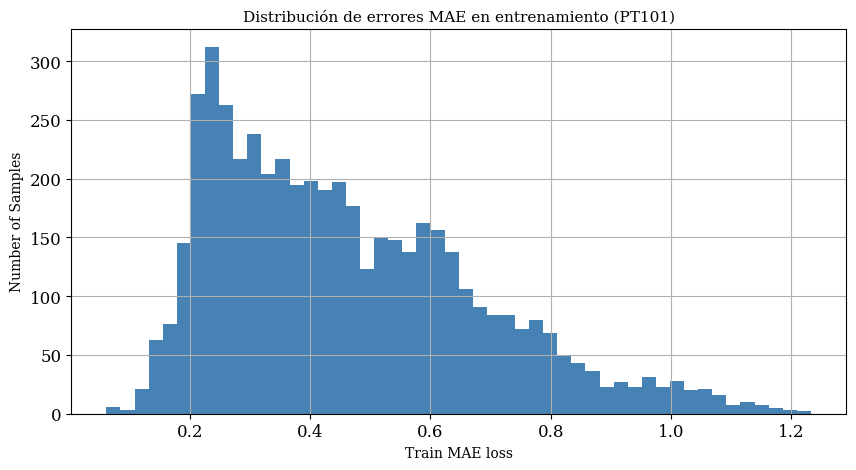

Reconstruction error threshold (LSTM VAE): 3.328730649457347


In [ ]:
# === Cálculo del error MAE por secuencia ===
train_mae_loss_vae = np.mean(np.abs(pred - X), axis=1)

# === Histograma de errores ===
plt.figure(figsize=(10, 5))
plt.hist(train_mae_loss_vae, bins=50, color='steelblue')
plt.xlabel('Train MAE loss')
plt.ylabel('Number of Samples')
plt.title('Distribución de errores MAE en entrenamiento (PT101)')
plt.grid(True)
plt.show()

# === Umbral basado en el máximo
threshold_lstm_vae = np.max(train_mae_loss_vae)*2.7
print('Reconstruction error threshold (LSTM VAE):', threshold_lstm_vae)


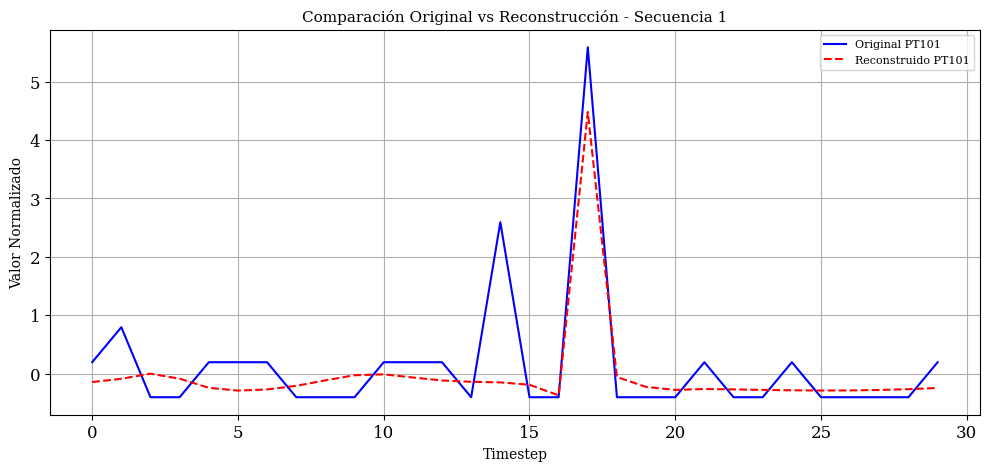

In [ ]:
import matplotlib.pyplot as plt

# Seleccionar una secuencia para graficar
index = 1  # cambia esto si quieres ver otra secuencia
original_sequence = X[index]
reconstructed_sequence = pred[index]

# Graficar la secuencia original y la reconstruida
plt.figure(figsize=(12, 5))
plt.plot(original_sequence, label='Original PT101', color='blue')
plt.plot(reconstructed_sequence, label='Reconstruido PT101', color='red', linestyle='--')
plt.title(f'Comparación Original vs Reconstrucción - Secuencia {index}')
plt.xlabel('Timestep')
plt.ylabel('Valor Normalizado')
plt.legend()
plt.grid(True)
plt.show()

156/156 ━━━━━━━━━━━━━━━━━━━━ 5s 31ms/step


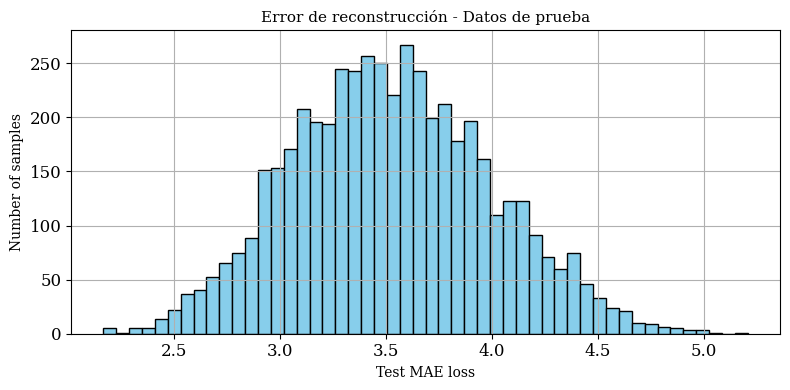

In [ ]:
vector_test_vae = vectores_anormales_vae['PT101'].reshape(-1, 1)

# Escalar
scaled_test_vae = scaler_lstm_vae.transform(vector_test_vae)

# Crear secuencias
def create_sequences(data, time_steps=30):
    return np.array([data[i:i + time_steps] for i in range(len(data) - time_steps)])

X_test = create_sequences(scaled_test_vae, time_steps)

# === Predicción y evaluación ===
X_test_pred = model_lstm_vae.predict(X_test, verbose=1)
test_mae_loss_vae = np.mean(np.abs(X_test_pred - X_test), axis=1)

# === Gráfica del error de reconstrucción ===
plt.figure(figsize=(8, 4))
plt.hist(test_mae_loss_vae, bins=50, color='skyblue', edgecolor='black')
plt.xlabel('Test MAE loss')
plt.ylabel('Number of samples')
plt.title('Error de reconstrucción - Datos de prueba')
plt.grid(True)
plt.tight_layout()
plt.show()

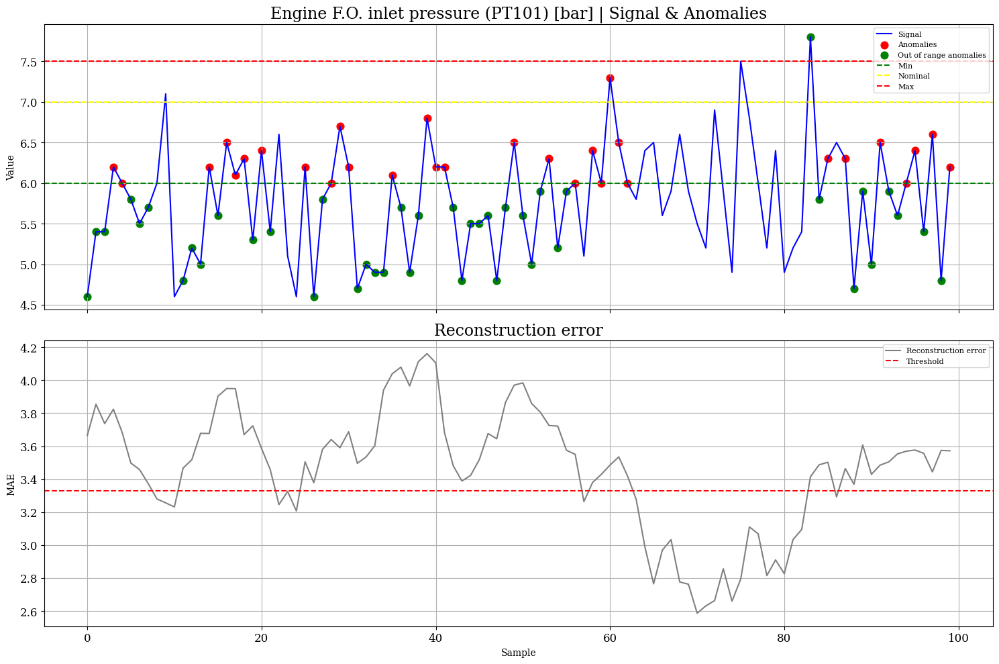

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# === Ajustes globales de estilo ===
plt.rcParams.update({
    'axes.titlesize': 17,    # Tamaño títulos de subgráficos
    'axes.labelsize': 10,    # Tamaño etiquetas de ejes
    'xtick.labelsize': 12,   # Tamaño números eje X
    'ytick.labelsize': 12,   # Tamaño números eje Y
    'legend.fontsize': 8,    # Tamaño leyenda
    'figure.titlesize': 10   # Tamaño título general
})

TIME_STEPS = 30
anomaly_df_lstm_vae_2 = df_vectores_anormales_vae[TIME_STEPS:].copy().reset_index(drop=True)

# Agregar métricas de error y umbral
anomaly_df_lstm_vae_2['loss'] = test_mae_loss_vae
anomaly_df_lstm_vae_2['threshold'] = threshold_lstm_vae
anomaly_df_lstm_vae_2['anomaly'] = anomaly_df_lstm_vae_2['loss'] > anomaly_df_lstm_vae_2['threshold']

# === Parámetros de estilo y diccionarios de idioma ===
usar_formales_2 = True  # True = inglés, False = español
segmento_longitud = 100  # número de valores a mostrar por corrida

if usar_formales_2:
    nombres = nombres_formales_2
    textos = {
        "signal": "Signal",
        "anom_in": "Anomalies",
        "anom_out": "Out of range anomalies",
        "loss": "Reconstruction error",
        "threshold": "Threshold",
        "xlabel": "Sample",
        "ylabel_signal": "Value",
        "ylabel_loss": "MAE"
    }
else:
    nombres = nombres_formales_3
    textos = {
        "signal": "Señal",
        "anom_in": "Anomalía detectada",
        "anom_out": "Anomalía fuera de rango",
        "loss": "Error de reconstrucción",
        "threshold": "Umbral",
        "xlabel": "Muestra",
        "ylabel_signal": "Valor",
        "ylabel_loss": "MAE"
    }

# === Nombre formal de la variable ===
variable1 = 'PT101'
nombre_formal = nombres.get(variable1, variable1)

# === Seleccionar segmento aleatorio ===
total_muestras = len(anomaly_df_lstm_vae_2)
if total_muestras <= segmento_longitud:
    inicio = 0
    fin = total_muestras
else:
    inicio = np.random.randint(0, total_muestras - segmento_longitud)
    fin = inicio + segmento_longitud

segmento_df = anomaly_df_lstm_vae_2.iloc[inicio:fin].reset_index(drop=True)

# Crear eje horizontal desde 0
x = np.arange(len(segmento_df))

# Valores hardcodeados
valor_min = 6
valor_nom = 7
valor_max = 7.5

# === Crear figura y subplots ===
fig, axs = plt.subplots(2, 1, figsize=(15, 10), sharex=True)

# Gráfico 1: Señal original con anomalías detectadas
axs[0].plot(x, segmento_df[variable1], color='blue', label=textos["signal"])

# Índices de anomalías en el segmento
anomalies_idx = segmento_df.index[segmento_df['anomaly'] == True].to_numpy()
dentro_rango_idx = anomalies_idx
fuera_rango_idx = np.array([])

# Separar anomalías fuera de rango
fuera_rango_idx = anomalies_idx[(segmento_df[variable1].iloc[anomalies_idx] < valor_min) |
                                (segmento_df[variable1].iloc[anomalies_idx] > valor_max)]
dentro_rango_idx = np.setdiff1d(anomalies_idx, fuera_rango_idx)

# Graficar puntos como círculos
if len(dentro_rango_idx) > 0:
    axs[0].scatter(x[dentro_rango_idx],
                   segmento_df.loc[dentro_rango_idx, variable1],
                   color='red', label=textos["anom_in"], marker='o', s=60)
if len(fuera_rango_idx) > 0:
    axs[0].scatter(x[fuera_rango_idx],
                   segmento_df.loc[fuera_rango_idx, variable1],
                   color='green', label=textos["anom_out"], marker='o', s=60)

# Líneas de rangos hardcodeadas
axs[0].axhline(valor_min, color='green', linestyle='--', label='Min')
axs[0].axhline(valor_nom, color='yellow', linestyle='--', label='Nominal')
axs[0].axhline(valor_max, color='red', linestyle='--', label='Max')

# Títulos y ejes
axs[0].set_title(f'{nombre_formal} | {textos["signal"]} & {textos["anom_in"]}')
axs[0].set_ylabel(textos["ylabel_signal"])
axs[0].grid(True)

# Solo la primera con leyenda
handles, labels = axs[0].get_legend_handles_labels()
by_label = dict(zip(labels, handles))
axs[0].legend(by_label.values(), by_label.keys())

# Gráfico 2: Error de reconstrucción
axs[1].plot(x, segmento_df['loss'], color='gray', label=textos["loss"])
axs[1].axhline(y=threshold_lstm_vae, color='red', linestyle='--', label=textos["threshold"])
axs[1].set_title(textos["loss"])
axs[1].set_xlabel(textos["xlabel"])
axs[1].set_ylabel(textos["ylabel_loss"])
axs[1].grid(True)
axs[1].legend()

plt.tight_layout()
plt.show()


In [ ]:
# Etiquetas: 0 = normal, 1 = anomalía
labels = (test_mae_loss_vae > threshold_lstm_vae).astype(int)

# Valores: reconstrucción (pueden verse como "puntos" en 1D)
X_silhouette_vae = test_mae_loss_vae.reshape(-1, 1)  # debe ser 2D

# Calcular Silhouette
score_vae = silhouette_score(X_silhouette_vae, labels)
print(f"Silhouette Score: {score_vae:.4f}")

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:1408: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


Silhouette Score: 0.4705


#LTSM MULTIVARIABLES

In [ ]:
#No correr#

import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dropout, RepeatVector, TimeDistributed, Dense
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import silhouette_score
import joblib
import pandas as pd
from google.colab import files

# === Subsystems ===
subsystems = {
    'Cooling system': ['PT401', 'TE401', 'PT471', 'TE600 - Carga', 'TE600 - Aire entrada al turbo'],
    'Fuel system': ['PT101', 'TE101'],
    'Lubrication system': ['RPM', "TE201", 'TE202', 'TE272', 'PDT243', 'PT271', 'XX001', 'XX002', 'XX012'],
    'Exhaust gas system': ['RPM', 'TE511', 'TE517', 'TE5011A']
}

# === Crear secuencias ===
def create_sequences(data, time_steps=30):
    sequences = []
    for i in range(len(data) - time_steps):
        sequences.append(data[i:i + time_steps])
    return np.array(sequences)

# === Definición del modelo LSTM-VAE ===
def build_lstm_vae(time_steps, n_features, latent_dim=128, dropout=0.2, activation='tanh'):
    model = Sequential([
        LSTM(latent_dim, activation=activation, input_shape=(time_steps, n_features), return_sequences=False),
        Dropout(dropout),
        RepeatVector(time_steps),
        LSTM(latent_dim, activation=activation, return_sequences=True),
        Dropout(dropout),
        TimeDistributed(Dense(n_features))
    ])
    model.compile(optimizer='adam', loss='mse')
    return model

# === Grid search ===
param_grid = {
    "latent_dim": [64, 128],
    "dropout": [0.2, 0.3],
    "activation": ['tanh', 'relu']
}

best_models = {}
results = []

time_steps = 30
epochs = 50
batch_size = 32

for subsystem, variables in subsystems.items():
    print(f"\n=== Entrenando subsistema: {subsystem} ===")
    try:
        # --- Datos normales ---
        vector_normal = np.stack([vectores_por_variable_vae[var] for var in variables], axis=1)
        scaler = MinMaxScaler()
        scaled_normal = scaler.fit_transform(vector_normal)
        X_train = create_sequences(scaled_normal, time_steps)

        # --- Datos anormales ---
        vector_anormal = np.stack([vectores_anormales_vae[var] for var in variables], axis=1)
        scaled_anormal = scaler.transform(vector_anormal)
        X_test = create_sequences(scaled_anormal, time_steps)

        best_score = -1
        best_model = None
        best_params = None

        # Grid search manual
        for latent_dim in param_grid["latent_dim"]:
            for dropout in param_grid["dropout"]:
                for activation in param_grid["activation"]:
                    print(f"Probando config: latent={latent_dim}, dropout={dropout}, act={activation}")

                    model = build_lstm_vae(time_steps, X_train.shape[2], latent_dim, dropout, activation)
                    model.fit(X_train, X_train,
                              epochs=epochs,
                              batch_size=batch_size,
                              validation_split=0.1,
                              shuffle=False,
                              verbose=0)

                    # Reconstrucciones
                    reconstructions = model.predict(X_test, verbose=0)
                    errors = np.mean(np.square(X_test - reconstructions), axis=(1,2))

                    # Silhouette score
                    labels = (errors > np.median(errors)).astype(int)  # cluster por error
                    try:
                        score = silhouette_score(errors.reshape(-1,1), labels)
                    except:
                        score = -1

                    print(f"Silhouette score: {score:.4f}")

                    if score > best_score:
                        best_score = score
                        best_model = model
                        best_params = (latent_dim, dropout, activation)

        print(f"Mejor configuración {subsystem}: {best_params} con Silhouette={best_score:.4f}")

        # Guardar modelo y scaler
        model_path = f"{subsystem.replace(' ','_')}_best_model.h5"
        scaler_path = f"{subsystem.replace(' ','_')}_scaler.pkl"

        best_model.save(model_path)
        joblib.dump(scaler, scaler_path)

        best_models[subsystem] = (model_path, scaler_path)

        # Guardar resultados para Excel
        results.append({
            "Subsystem": subsystem,
            "Latent_dim": best_params[0],
            "Dropout": best_params[1],
            "Activation": best_params[2],
            "Silhouette": best_score
        })

    except Exception as e:
        print(f"Error en {subsystem}: {e}")

# === Guardar Excel con los mejores hiperparámetros ===
df_results = pd.DataFrame(results)
excel_path = "best_models_results.xlsx"
df_results.to_excel(excel_path, index=False)

# === Descargar modelos, scalers y Excel al PC ===
files.download(excel_path)
for subsystem, (model_path, scaler_path) in best_models.items():
    files.download(model_path)
    files.download(scaler_path)




=== Entrenando subsistema: Cooling system ===
Probando config: latent=64, dropout=0.2, act=tanh


/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Silhouette score: 0.5356
Probando config: latent=64, dropout=0.2, act=relu


/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Silhouette score: 0.4298
Probando config: latent=64, dropout=0.3, act=tanh


...

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

#SUSBSISTEMA DE COMBUSTIBLE

In [ ]:
# === Parámetros ===
time_steps = 30
variables_objetivo = ['PT101', 'TE101']

# === Extraer vectores para ambas variables ===
vector_multivariable_vae = np.stack(
    [vectores_por_variable_vae[var] for var in variables_objetivo],
    axis=1
)

# === Escalado multivariable ===
scaler_lstm_vae = MinMaxScaler()
scaled_vector_vae = scaler_lstm_vae.fit_transform(vector_multivariable_vae)

# === Crear secuencias ===
def create_sequences(data, time_steps=30):
    sequences = []
    for i in range(len(data) - time_steps):
        sequences.append(data[i:i + time_steps])
    return np.array(sequences)

X_lstm_vae = create_sequences(scaled_vector_vae, time_steps)

In [ ]:
# === Parámetros ===
time_steps = 30
variables_objetivo = ['PT101', 'TE101']

# === Extraer vectores para ambas variables ===
vector_multivariable_vae = np.stack(
    [vectores_por_variable_vae[var] for var in variables_objetivo],
    axis=1
)

# === Escalado multivariable ===
scaler_lstm_vae = MinMaxScaler()
scaled_vector_vae = scaler_lstm_vae.fit_transform(vector_multivariable_vae)

# === Crear secuencias ===
def create_sequences(data, time_steps=30):
    sequences = []
    for i in range(len(data) - time_steps):
        sequences.append(data[i:i + time_steps])
    return np.array(sequences)

X_lstm_vae = create_sequences(scaled_vector_vae, time_steps)
np.random.seed(42)
tf.random.set_seed(42)


print(f"Forma de las secuencias: {X_lstm_vae.shape}")  # (n_muestras, time_steps, n_variables)

# === Construcción del modelo LSTM Autoencoder ===
n_features = X_lstm_vae.shape[2]

model_lstm_vae = Sequential([
    LSTM(128, activation='tanh', input_shape=(time_steps, n_features), return_sequences=False),
    Dropout(0.2),
    RepeatVector(time_steps),
    LSTM(128, activation='tanh', return_sequences=True),
    Dropout(0.2),
    TimeDistributed(Dense(n_features))
])

model_lstm_vae.compile(optimizer='adam', loss='mse')

# === Entrenamiento ===
history_lstm_vae = model_lstm_vae.fit(
    X_lstm_vae, X_lstm_vae,
    epochs=50,
    batch_size=32,
    validation_split=0.1,
    shuffle=False,
    verbose=1
)


Forma de las secuencias: (4970, 30, 2)
Epoch 1/50


/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


140/140 ━━━━━━━━━━━━━━━━━━━━ 23s 117ms/step - loss: 0.0275 - val_loss: 0.0201
Epoch 2/50
140/140 ━━━━━━━━━━━━━━━━━━━━ 21s 117ms/step - loss: 0.0196 - val_loss: 0.0196
Epoch 3/50
140/140 ━━━━━━━━━━━━━━━━━━━━ 15s 104ms/step - loss: 0.0191 - val_loss: 0.0194
Epoch 4/50
140/140 ━━━━━━━━━━━━━━━━━━━━ 15s 104ms/step - loss: 0.0189 - val_loss: 0.0193
Epoch 5/50
140/140 ━━━━━━━━━━━━━━━━━━━━ 22s 116ms/step - loss: 0.0186 - val_loss: 0.0189
Epoch 6/50
140/140 ━━━━━━━━━━━━━━━━━━━━ 19s 139ms/step - loss: 0.0187 - val_loss: 0.0188
Epoch 7/50
140/140 ━━━━━━━━━━━━━━━━━━━━ 18s 124ms/step - loss: 0.0182 - val_loss: 0.0186
Epoch 8/50
140/140 ━━━━━━━━━━━━━━━━━━━━ 15s 110ms/step - loss: 0.0181 - val_loss: 0.0182
Epoch 9/50
140/140 ━━━━━━━━━━━━━━━━━━━━ 23s 126ms/step - loss: 0.0177 - val_loss: 0.0182
Epoch 10/50
140/140 ━━━━━━━━━━━━━━━━━━━━ 18s 110ms/step - loss: 0.0176 - val_loss: 0.0178
Epoch 11/50
140/140 ━━━━━━━━━━━━━━━━━━━━ 15s 109ms/step - loss: 0.0174 - val_loss: 0.0174
Epoch 12/50
140/140 ━━━━━━━━━━

In [ ]:
#No correr#
import joblib
import json
from tensorflow.keras.models import load_model

# === Guardar el scaler ===
joblib.dump(scaler_lstm_vae, 'scaler_lstm_combustible.pkl')

# === Guardar el modelo ===
model_lstm_vae.save('modelo_lstm_combustible.h5')

NameError: name 'scaler_lstm_vae' is not defined

In [ ]:
import joblib
from tensorflow.keras.models import load_model

# === Cargar el scaler ===
scaler_lstm_vae = joblib.load('scaler_lstm_combustible.pkl')

# === Cargar el modelo ===
model_lstm_vae = load_model('modelo_lstm_combustible.h5', compile=False)

In [ ]:
# === Predicción sobre los datos de entrenamiento ===
X_lstm_vae_pred = model_lstm_vae.predict(X_lstm_vae)

# === Cálculo del MAE por muestra (promediando todas las variables y pasos temporales) ===
mae_per_sample = np.mean(np.abs(X_lstm_vae_pred - X_lstm_vae), axis=(1, 2))

# === Threshold como el MAE máximo observado en entrenamiento ===
threshold_mae = np.max(mae_per_sample)
print(f"Threshold de MAE: {threshold_mae:.4f}")


156/156 ━━━━━━━━━━━━━━━━━━━━ 7s 43ms/step
Threshold de MAE: 0.3500


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.gridspec import GridSpec

# === 1. Construir el vector multivariable desde el diccionario ===
vector_multivariable_anormal = np.stack([
    vectores_anormales_vae['PT101'],
    vectores_anormales_vae['TE101']
], axis=1)  # (N, 2)

# === 2. Escalar con el mismo scaler que se usó para entrenar ===
scaled_anormal = scaler_lstm_vae.transform(vector_multivariable_anormal)

# === 3. Crear secuencias ===
X_anormal = create_sequences(scaled_anormal, time_steps)  # (M, time_steps, 2)

# === 4. Hacer predicciones ===
X_anormal_pred = model_lstm_vae.predict(X_anormal)

# === 5. Calcular MAE por variable ===
mae_por_variable = np.mean(np.abs(X_anormal_pred - X_anormal), axis=1)  # (M, 2)

# === 6. Definir thresholds distintos ===
thresholds = {"PT101": 0.36, "TE101": 0.36}

# === 7. Comparar cada variable contra su threshold ===
anomaly_flags = {}
anomaly_indices = {}

for i, var in enumerate(['PT101', 'TE101']):
    anomaly_flags[var] = mae_por_variable[:, i] > thresholds[var]
    anomaly_indices[var] = np.where(anomaly_flags[var])[0] + time_steps  # ajustar por el shift



156/156 ━━━━━━━━━━━━━━━━━━━━ 5s 29ms/step


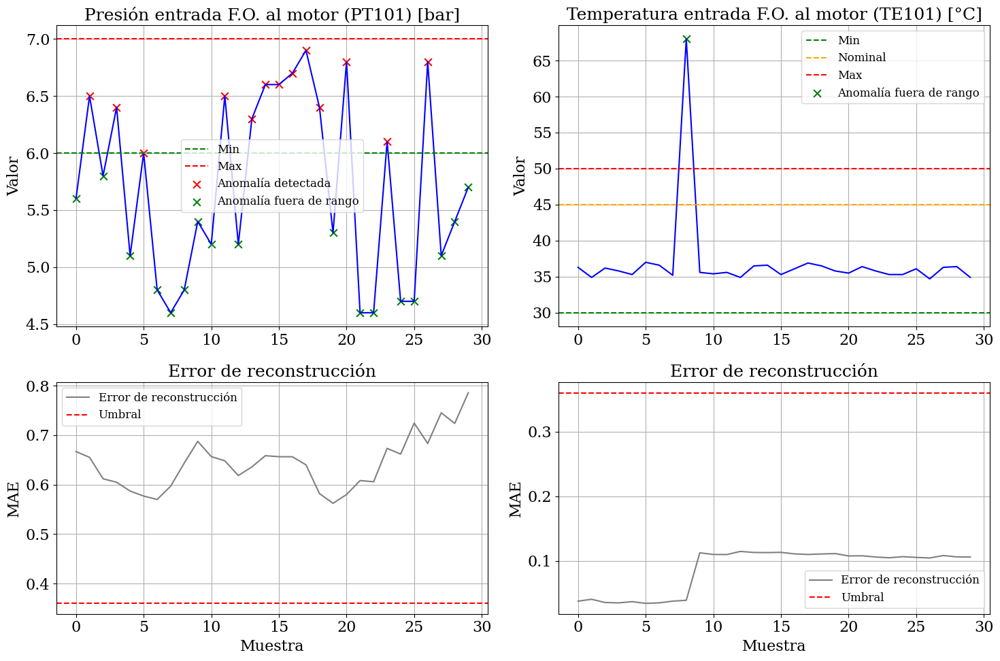

In [ ]:
usar_formales_2 = False  # True = inglés, False = español
if usar_formales_2:
    nombres = nombres_formales_2
    textos = {
        "anom_in": "Detected anomaly",
        "anom_out": "Out-of-range anomaly",
        "loss": "Reconstruction error",
        "threshold": "Threshold",
        "xlabel": "Sample",
        "ylabel_signal": "Value",
        "ylabel_loss": "MAE"
    }
else:
    nombres = nombres_formales_3
    textos = {
        "anom_in": "Anomalía detectada",
        "anom_out": "Anomalía fuera de rango",
        "loss": "Error de reconstrucción",
        "threshold": "Umbral",
        "xlabel": "Muestra",
        "ylabel_signal": "Valor",
        "ylabel_loss": "MAE"
    }

variables = ['PT101', 'TE101']

# =========================================================
# === 9. Selección aleatoria de un tramo de 100 puntos  ===
# =========================================================
segment_length = 30
max_start = len(vector_multivariable_anormal) - segment_length
start_idx = np.random.randint(0, max_start)
end_idx = start_idx + segment_length

x_plot = np.arange(segment_length)

# --- Señales ---
vector_plot = vector_multivariable_anormal[start_idx:end_idx]

# --- MAE (ajustar shift por time_steps) ---
mae_start = max(0, start_idx - time_steps)
mae_end = mae_start + segment_length
mae_plot = mae_por_variable[mae_start:mae_end]  # alineado

# Ajustar también los índices de anomalías a este tramo
anomaly_indices_plot = {}
for i, var in enumerate(variables):
    idxs = anomaly_indices[var]
    anomaly_indices_plot[var] = idxs[(idxs >= start_idx) & (idxs < end_idx)] - start_idx

# =========================================================
# === 10. Layout con GridSpec (2 filas, 2 columnas) ===
# =========================================================
plt.rcParams['font.size'] = 16
plt.rcParams['font.family'] = 'serif'

fig = plt.figure(figsize=(15, 10))
gs = GridSpec(2, 2, height_ratios=[1.3, 1], figure=fig)

# --- Señales (fila 0) ---
for i, var in enumerate(variables):
    ax = fig.add_subplot(gs[0, i])
    ax.plot(x_plot, vector_plot[:, i], color='blue')

    # anomalías dentro/fuera de rango (solo dentro del tramo)
    dentro_rango_idx = anomaly_indices_plot[var]
    fuera_rango_idx = np.array([])

    if var in rangos_resultado:
        r = rangos_resultado[var]
        vmin, vnom, vmax = r.get("Valor mínimo"), r.get("Valor nominal"), r.get("Valor máximo")
        if vmin is not None and vmax is not None:
            # --- aquí el cambio importante ---
            if var == "TE101":
                # todos los puntos fuera de rango en TE101 siempre verdes
                fuera_rango_idx = np.where((vector_plot[:, i] < vmin) |
                                           (vector_plot[:, i] > vmax))[0]
                dentro_rango_idx = np.array([])  # no mostramos rojos
            else:
                fuera_rango_idx = dentro_rango_idx[(vector_plot[dentro_rango_idx, i] < vmin) |
                                                   (vector_plot[dentro_rango_idx, i] > vmax)]
                dentro_rango_idx = np.setdiff1d(dentro_rango_idx, fuera_rango_idx)

        # Líneas de rangos
        if vmin is not None:
            ax.axhline(vmin, color='green', linestyle='--', label='Min')
        if vnom is not None:
            ax.axhline(vnom, color='orange', linestyle='--', label='Nominal')
        if vmax is not None:
            ax.axhline(vmax, color='red', linestyle='--', label='Max')

    # --- Scatter de anomalías ---
    if len(dentro_rango_idx) > 0:
        ax.scatter(dentro_rango_idx,
                   vector_plot[dentro_rango_idx, i],
                   color='red', marker='x', s=60, label=textos["anom_in"])
    if len(fuera_rango_idx) > 0:
        ax.scatter(fuera_rango_idx,
                   vector_plot[fuera_rango_idx, i],
                   color='green', marker='x', s=60, label=textos["anom_out"])

    ax.set_title(f"{nombres[var]}", fontsize=18)
    ax.set_ylabel(textos["ylabel_signal"], fontsize=16)
    ax.grid(True)

    # leyenda simplificada
    handles, labels = ax.get_legend_handles_labels()
    by_label = dict(zip(labels, handles))
    ax.legend(by_label.values(), by_label.keys(), fontsize=12)

# --- MAE por variable (fila 1) ---
for i, var in enumerate(variables):
    ax_mae = fig.add_subplot(gs[1, i])
    ax_mae.plot(x_plot, mae_plot[:, i], color="gray", label=textos["loss"])
    ax_mae.axhline(y=thresholds[var], color="red", linestyle="--", label=textos["threshold"])
    ax_mae.set_title(f"{textos['loss']}", fontsize=18)
    ax_mae.set_xlabel(textos["xlabel"], fontsize=16)
    ax_mae.set_ylabel(textos["ylabel_loss"], fontsize=16)
    ax_mae.grid(True)
    ax_mae.legend(fontsize=12)

plt.tight_layout()
plt.show()


In [ ]:
# === Concatenar por variable ===
vector_pt101_mixto = np.concatenate([
    vectores_por_variable_vae['PT101'][:2500],
    vectores_anormales_vae['PT101'][:2500]
])

vector_te101_mixto = np.concatenate([
    vectores_por_variable_vae['TE101'][:2500],
    vectores_anormales_vae['TE101'][:2500]
])

# === Combinar en array multivariable ===
vector_multivariable_mixto = np.stack([vector_pt101_mixto, vector_te101_mixto], axis=1)  # (5000, 2)
# === Escalado con el scaler entrenado
scaled_mixto = scaler_lstm_vae.transform(vector_multivariable_mixto)

# === Crear secuencias
X_mixto = create_sequences(scaled_mixto, time_steps)

# === Predicción
X_mixto_pred = model_lstm_vae.predict(X_mixto)

# === Cálculo de MAE
mae_mixto = np.mean(np.abs(X_mixto_pred - X_mixto), axis=(1, 2))

# === Detectar anomalías
anomaly_flags_mixto = mae_mixto > threshold_mae
anomaly_indices_mixto = np.where(anomaly_flags_mixto)[0] + time_steps

print(f"Anomalías detectadas: {np.sum(anomaly_flags_mixto)} de {len(mae_mixto)} muestras")



156/156 ━━━━━━━━━━━━━━━━━━━━ 4s 28ms/step
Anomalías detectadas: 1010 de 4970 muestras


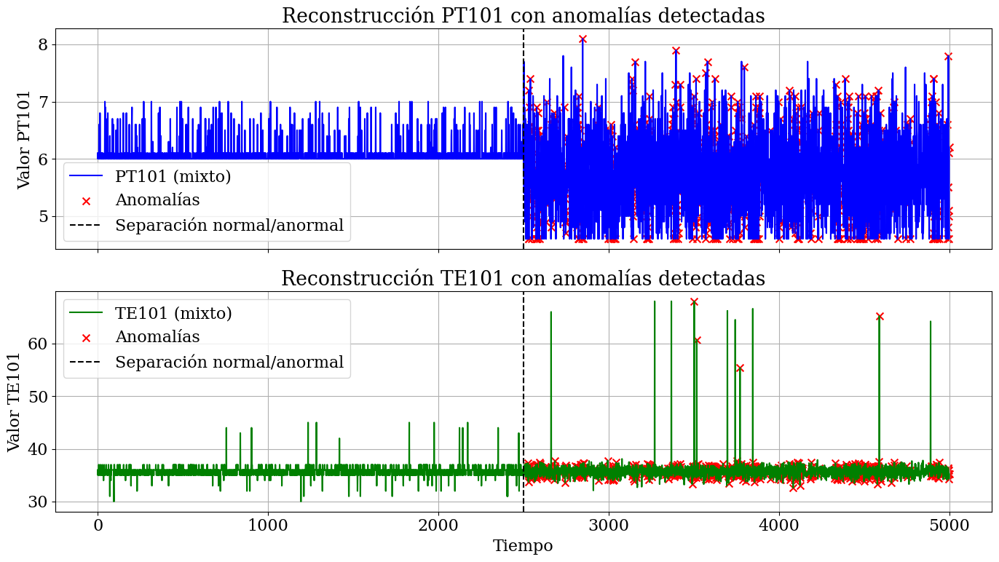

In [ ]:
import matplotlib.pyplot as plt

fig, axs = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

# === Subplot PT101
axs[0].plot(vector_pt101_mixto, label='PT101 (mixto)', color='blue')
axs[0].scatter(anomaly_indices_mixto, vector_pt101_mixto[anomaly_indices_mixto],
               color='red', marker='x', s=50, label='Anomalías')
axs[0].axvline(x=2500, color='black', linestyle='--', label='Separación normal/anormal')
axs[0].set_ylabel('Valor PT101')
axs[0].set_title('Reconstrucción PT101 con anomalías detectadas')
axs[0].legend()
axs[0].grid(True)

# === Subplot TE101
axs[1].plot(vector_te101_mixto, label='TE101 (mixto)', color='green')
axs[1].scatter(anomaly_indices_mixto, vector_te101_mixto[anomaly_indices_mixto],
               color='red', marker='x', s=50, label='Anomalías')
axs[1].axvline(x=2500, color='black', linestyle='--', label='Separación normal/anormal')
axs[1].set_ylabel('Valor TE101')
axs[1].set_title('Reconstrucción TE101 con anomalías detectadas')
axs[1].legend()
axs[1].grid(True)

# === Ajustes finales
plt.xlabel('Tiempo')
plt.tight_layout()
plt.show()


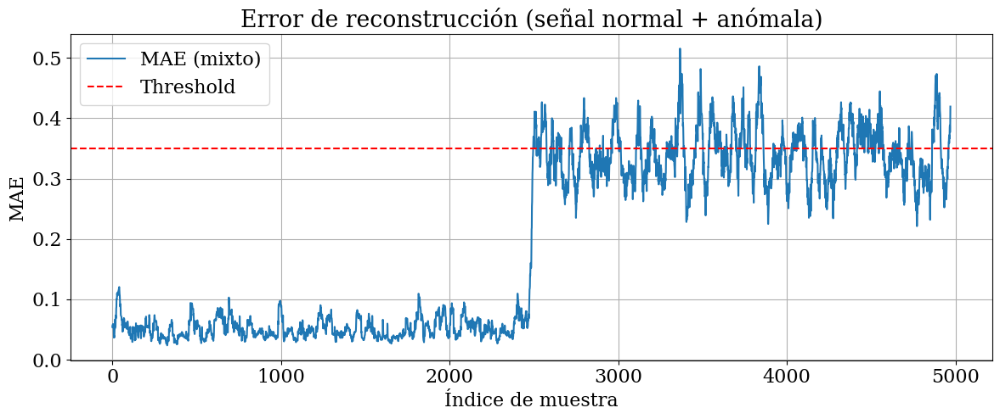

In [ ]:
plt.figure(figsize=(14, 5))
plt.plot(mae_mixto, label='MAE (mixto)')
plt.axhline(threshold_mae, color='red', linestyle='--', label='Threshold')
plt.title('Error de reconstrucción (señal normal + anómala)')
plt.xlabel('Índice de muestra')
plt.ylabel('MAE')
plt.legend()
plt.grid(True)
plt.show()


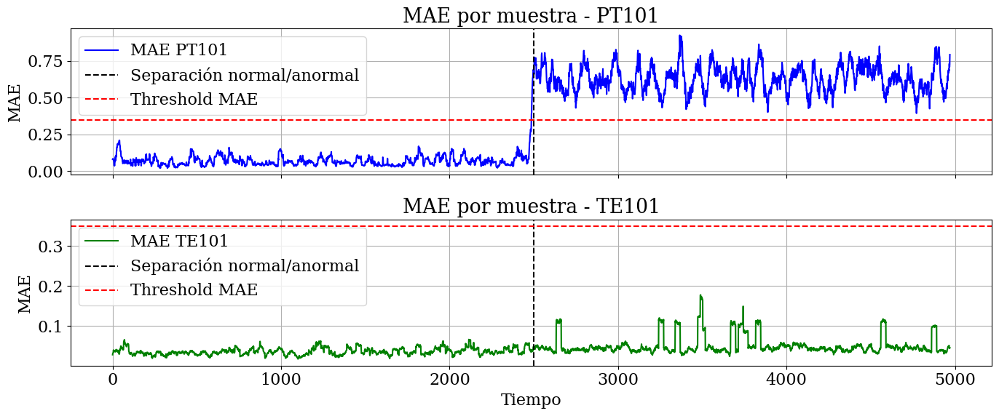

In [ ]:
mae_mixto = np.mean(np.abs(X_mixto_pred - X_mixto), axis=(1))
import matplotlib.pyplot as plt

fig, axs = plt.subplots(2, 1, figsize=(14, 6), sharex=True)

# === MAE para PT101
axs[0].plot(mae_mixto[:, 0], label='MAE PT101', color='blue')
axs[0].axvline(x=2500, color='black', linestyle='--', label='Separación normal/anormal')
axs[0].axhline(y=threshold_mae, color='red', linestyle='--', label='Threshold MAE')
axs[0].set_title('MAE por muestra - PT101')
axs[0].set_ylabel('MAE')
axs[0].legend()
axs[0].grid(True)

# === MAE para TE101
axs[1].plot(mae_mixto[:, 1], label='MAE TE101', color='green')
axs[1].axvline(x=2500, color='black', linestyle='--', label='Separación normal/anormal')
axs[1].axhline(y=threshold_mae, color='red', linestyle='--', label='Threshold MAE')
axs[1].set_title('MAE por muestra - TE101')
axs[1].set_ylabel('MAE')
axs[1].set_xlabel('Tiempo')
axs[1].legend()
axs[1].grid(True)

plt.tight_layout()
plt.show()

#SUBSISTEMA DE GASES DE ESCAPE

In [ ]:
# === Parámetros ===
time_steps = 30
variables_gases = ['TE511', 'TE517', 'TE5011A', 'RPM']

# === Extraer vectores para las variables del sistema de gases ===
vector_gases_multivariable = np.stack(
    [vectores_por_variable_vae[var] for var in variables_gases],
    axis=1
)

# === Escalado multivariable ===
from sklearn.preprocessing import MinMaxScaler
scaler_gases = MinMaxScaler()
vector_gases_scaled = scaler_gases.fit_transform(vector_gases_multivariable)

# === Crear secuencias ===
def create_sequences(data, time_steps=30):
    sequences = []
    for i in range(len(data) - time_steps):
        sequences.append(data[i:i + time_steps])
    return np.array(sequences)

X_gases = create_sequences(vector_gases_scaled, time_steps)


In [ ]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dropout, RepeatVector, TimeDistributed, Dense

# === Fijar semillas para reproducibilidad ===
np.random.seed(42)
tf.random.set_seed(42)

print(f"Forma de las secuencias del sistema de gases: {X_gases.shape}")  # (n_muestras, time_steps, n_variables)

# === Construcción del modelo LSTM Autoencoder para sistema de gases ===
n_features_gases = X_gases.shape[2]

model_lstm_gases = Sequential([
    LSTM(128, activation='tanh', input_shape=(time_steps, n_features_gases), return_sequences=False),
    Dropout(0.2),
    RepeatVector(time_steps),
    LSTM(128, activation='tanh', return_sequences=True),
    Dropout(0.2),
    TimeDistributed(Dense(n_features_gases))
])

model_lstm_gases.compile(optimizer='adam', loss='mse')

# === Entrenamiento del modelo ===
history_lstm_gases = model_lstm_gases.fit(
    X_gases, X_gases,
    epochs=50,
    batch_size=32,
    validation_split=0.1,
    shuffle=False,
    verbose=1
)


Forma de las secuencias del sistema de gases: (4970, 30, 4)


/usr/local/lib/python3.11/dist-packages/keras/src/layers/rnn/rnn.py:200: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/50
140/140 ━━━━━━━━━━━━━━━━━━━━ 27s 149ms/step - loss: 0.1019 - val_loss: 0.0485
Epoch 2/50
140/140 ━━━━━━━━━━━━━━━━━━━━ 16s 111ms/step - loss: 0.0481 - val_loss: 0.0480
Epoch 3/50
140/140 ━━━━━━━━━━━━━━━━━━━━ 22s 120ms/step - loss: 0.0461 - val_loss: 0.0469
Epoch 4/50
140/140 ━━━━━━━━━━━━━━━━━━━━ 19s 110ms/step - loss: 0.0455 - val_loss: 0.0468
Epoch 5/50
140/140 ━━━━━━━━━━━━━━━━━━━━ 15s 110ms/step - loss: 0.0454 - val_loss: 0.0468
Epoch 6/50
140/140 ━━━━━━━━━━━━━━━━━━━━ 20s 108ms/step - loss: 0.0451 - val_loss: 0.0467
Epoch 7/50
140/140 ━━━━━━━━━━━━━━━━━━━━ 15s 108ms/step - loss: 0.0449 - val_loss: 0.0467
Epoch 8/50
140/140 ━━━━━━━━━━━━━━━━━━━━ 21s 111ms/step - loss: 0.0446 - val_loss: 0.0467
Epoch 9/50
140/140 ━━━━━━━━━━━━━━━━━━━━ 22s 122ms/step - loss: 0.0445 - val_loss: 0.0466
Epoch 10/50
140/140 ━━━━━━━━━━━━━━━━━━━━ 17s 121ms/step - loss: 0.0444 - val_loss: 0.0467
Epoch 11/50
140/140 ━━━━━━━━━━━━━━━━━━━━ 19s 109ms/step - loss: 0.0442 - val_loss: 0.0466
Epoch 12/50
140/140

In [ ]:
#No correr#
import joblib
import json
from tensorflow.keras.models import load_model

# === Guardar el scaler ===
joblib.dump(scaler_gases, 'scaler_lstm_vae_gases.pkl')

# === Guardar el modelo ===
model_lstm_gases.save('modelo_lstm_vae_gases.h5')

In [ ]:
import joblib
from tensorflow.keras.models import load_model

# === Cargar el scaler ===
scaler_gases = joblib.load('scaler_lstm_vae_gases.pkl')

# === Cargar el modelo sin compilar ===
model_lstm_gases = load_model('modelo_lstm_vae_gases.h5', compile=False)

FileNotFoundError: [Errno 2] No such file or directory: 'scaler_lstm_vae_gases.pkl'

In [ ]:
# === Predicción sobre los datos de entrenamiento del sistema de gases ===
X_gases_pred = model_lstm_gases.predict(X_gases)

# === Cálculo del MAE por muestra (promediando todas las variables y pasos temporales) ===
mae_gases_por_muestra = np.mean(np.abs(X_gases_pred - X_gases), axis=(1, 2))

# === Threshold como el MAE máximo observado en entrenamiento ===
threshold_gases = np.max(mae_gases_por_muestra)
print(f"Threshold de MAE para el sistema de gases: {threshold_gases:.4f}")


156/156 ━━━━━━━━━━━━━━━━━━━━ 6s 32ms/step
Threshold de MAE para el sistema de gases: 0.2539


In [ ]:
# === 1. Construir el vector multivariable anormal del sistema de gases desde el diccionario
vector_gases_anormal = np.stack([
    vectores_anormales_vae['TE511'],
    vectores_anormales_vae['TE517'],
    vectores_anormales_vae['TE5011A'],
    vectores_anormales_vae['RPM']
], axis=1)  # (n_muestras, 4)

# === 2. Escalar con el mismo scaler usado para el entrenamiento
vector_gases_anormal_scaled = scaler_gases.transform(vector_gases_anormal)

# === 3. Crear secuencias
X_gases_anormal = create_sequences(vector_gases_anormal_scaled, time_steps)  # (n_muestras_seq, 30, 4)

# === 4. Hacer predicciones y calcular el MAE por muestra
X_gases_anormal_pred = model_lstm_gases.predict(X_gases_anormal)
mae_gases_anormal = np.mean(np.abs(X_gases_anormal_pred - X_gases_anormal), axis=(1, 2))

# === 5. Comparar con el threshold
anomaly_flags_gases = mae_gases_anormal > threshold_gases
anomaly_indices_gases = np.where(anomaly_flags_gases)[0] + time_steps  # Reajustar al índice del vector original

# === 6. Mostrar resumen
print(f"Se detectaron {np.sum(anomaly_flags_gases)} anomalías en el sistema de gases de {len(mae_gases_anormal)} muestras")

# === 7. Calcular Silhouette Score si hay al menos dos clases
labels_gases = anomaly_flags_gases.astype(int)
X_silhouette_gases = mae_gases_anormal.reshape(-1, 1)

if len(np.unique(labels_gases)) < 2:
    print("No se puede calcular Silhouette Score: todas las muestras tienen la misma etiqueta.")
else:
    score_gases = silhouette_score(X_silhouette_gases, labels_gases)
    print(f"Silhouette Score (sistema de gases): {score_gases:.4f}")

156/156 ━━━━━━━━━━━━━━━━━━━━ 4s 28ms/step
Se detectaron 0 anomalías en el sistema de gases de 4970 muestras
No se puede calcular Silhouette Score: todas las muestras tienen la misma etiqueta.


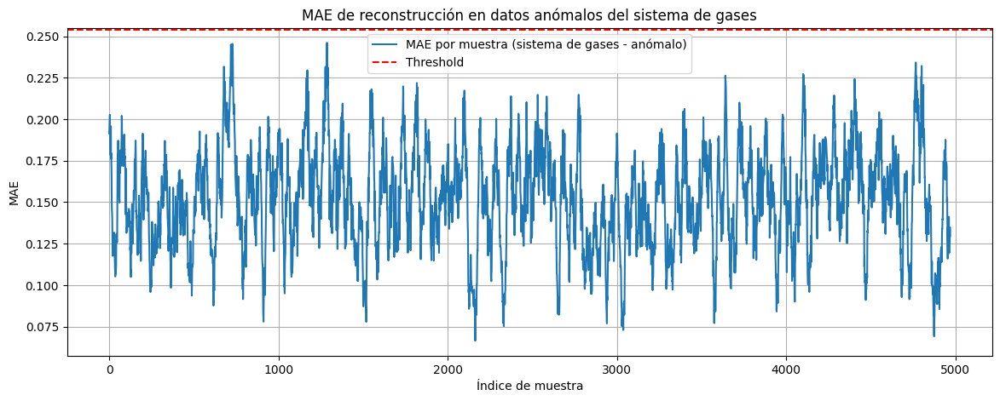

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))
plt.plot(mae_gases_anormal, label='MAE por muestra (sistema de gases - anómalo)')
plt.axhline(threshold_gases, color='red', linestyle='--', label='Threshold')
plt.title('MAE de reconstrucción en datos anómalos del sistema de gases')
plt.xlabel('Índice de muestra')
plt.ylabel('MAE')
plt.legend()
plt.grid(True)
plt.show()


In [ ]:
# === Concatenar por variable (2500 normales + 2500 anormales)
vector_te511_mixto = np.concatenate([
    vectores_por_variable_vae['TE511'][:2500],
    vectores_anormales_vae['TE511'][:2500]
])

vector_te517_mixto = np.concatenate([
    vectores_por_variable_vae['TE517'][:2500],
    vectores_anormales_vae['TE517'][:2500]
])

vector_te5011a_mixto = np.concatenate([
    vectores_por_variable_vae['TE5011A'][:2500],
    vectores_anormales_vae['TE5011A'][:2500]
])

vector_rpm_mixto = np.concatenate([
    vectores_por_variable_vae['RPM'][:2500],
    vectores_anormales_vae['RPM'][:2500]
])

# === Combinar en array multivariable
vector_gases_mixto = np.stack([
    vector_te511_mixto,
    vector_te517_mixto,
    vector_te5011a_mixto,
    vector_rpm_mixto
], axis=1)  # (5000, 4)

# === Escalado con el scaler entrenado
vector_gases_mixto_scaled = scaler_gases.transform(vector_gases_mixto)

# === Crear secuencias
X_gases_mixto = create_sequences(vector_gases_mixto_scaled, time_steps)

# === Predicción
X_gases_mixto_pred = model_lstm_gases.predict(X_gases_mixto)

# === Cálculo de MAE
mae_gases_mixto = np.mean(np.abs(X_gases_mixto_pred - X_gases_mixto), axis=(1, 2))

# === Detectar anomalías
anomaly_flags_gases_mixto = mae_gases_mixto > threshold_gases
anomaly_indices_gases_mixto = np.where(anomaly_flags_gases_mixto)[0] + time_steps

print(f"Anomalías detectadas en datos mixtos del sistema de gases: {np.sum(anomaly_flags_gases_mixto)} de {len(mae_gases_mixto)} muestras")


156/156 ━━━━━━━━━━━━━━━━━━━━ 4s 28ms/step
Anomalías detectadas en datos mixtos del sistema de gases: 0 de 4970 muestras


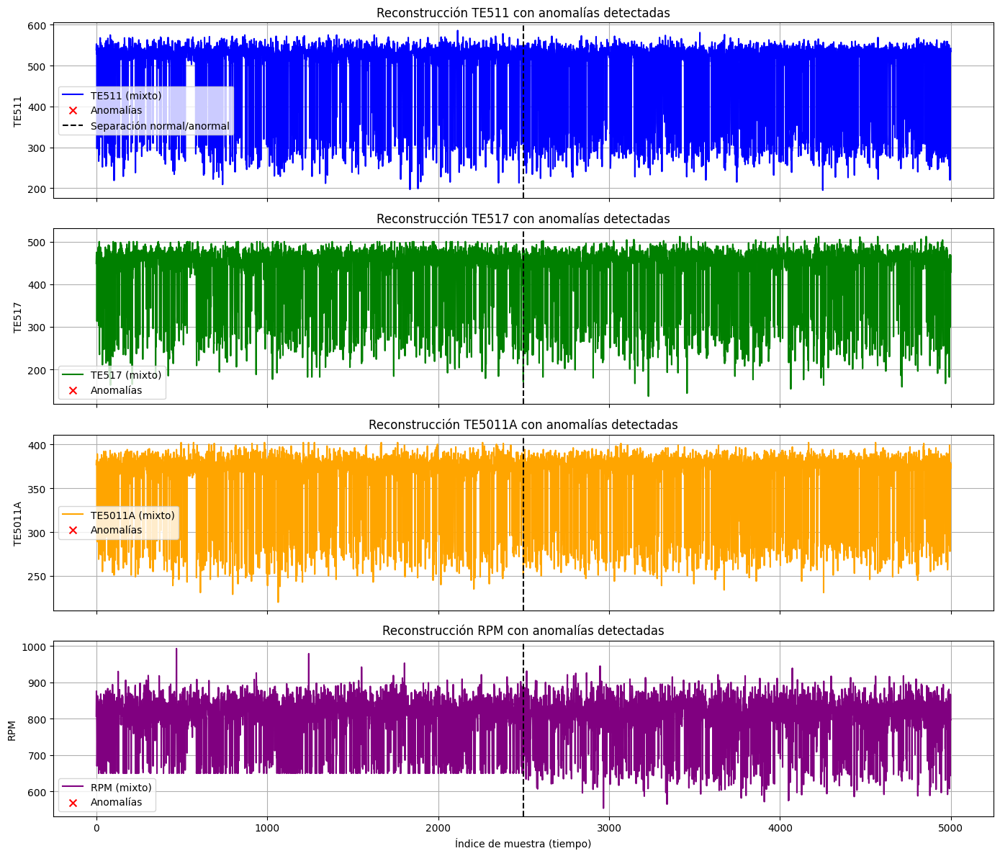

In [ ]:
fig, axs = plt.subplots(4, 1, figsize=(14, 12), sharex=True)

# === Subplot TE511
axs[0].plot(vector_te511_mixto, label='TE511 (mixto)', color='blue')
axs[0].scatter(anomaly_indices_gases_mixto, vector_te511_mixto[anomaly_indices_gases_mixto],
               color='red', marker='x', s=50, label='Anomalías')
axs[0].axvline(x=2500, color='black', linestyle='--', label='Separación normal/anormal')
axs[0].set_ylabel('TE511')
axs[0].set_title('Reconstrucción TE511 con anomalías detectadas')
axs[0].legend()
axs[0].grid(True)

# === Subplot TE517
axs[1].plot(vector_te517_mixto, label='TE517 (mixto)', color='green')
axs[1].scatter(anomaly_indices_gases_mixto, vector_te517_mixto[anomaly_indices_gases_mixto],
               color='red', marker='x', s=50, label='Anomalías')
axs[1].axvline(x=2500, color='black', linestyle='--')
axs[1].set_ylabel('TE517')
axs[1].set_title('Reconstrucción TE517 con anomalías detectadas')
axs[1].legend()
axs[1].grid(True)

# === Subplot TE5011A
axs[2].plot(vector_te5011a_mixto, label='TE5011A (mixto)', color='orange')
axs[2].scatter(anomaly_indices_gases_mixto, vector_te5011a_mixto[anomaly_indices_gases_mixto],
               color='red', marker='x', s=50, label='Anomalías')
axs[2].axvline(x=2500, color='black', linestyle='--')
axs[2].set_ylabel('TE5011A')
axs[2].set_title('Reconstrucción TE5011A con anomalías detectadas')
axs[2].legend()
axs[2].grid(True)

# === Subplot RPM
axs[3].plot(vector_rpm_mixto, label='RPM (mixto)', color='purple')
axs[3].scatter(anomaly_indices_gases_mixto, vector_rpm_mixto[anomaly_indices_gases_mixto],
               color='red', marker='x', s=50, label='Anomalías')
axs[3].axvline(x=2500, color='black', linestyle='--')
axs[3].set_ylabel('RPM')
axs[3].set_title('Reconstrucción RPM con anomalías detectadas')
axs[3].legend()
axs[3].grid(True)

# === Ajustes finales
plt.xlabel('Índice de muestra (tiempo)')
plt.tight_layout()
plt.show()

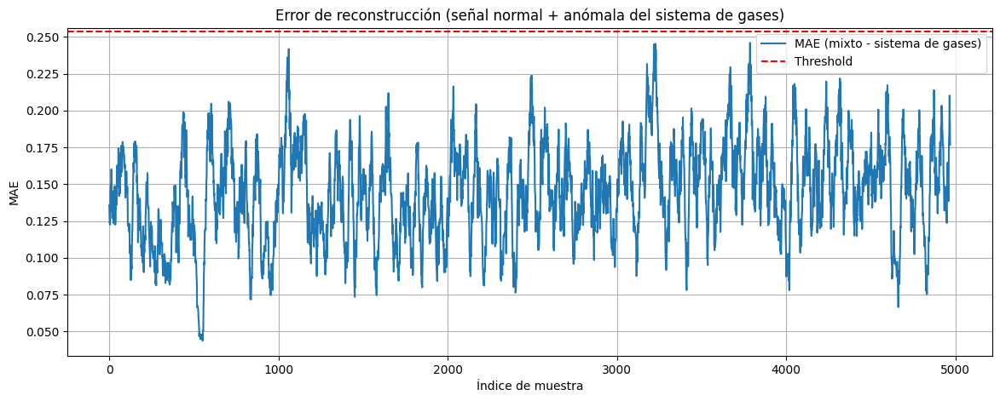

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))
plt.plot(mae_gases_mixto, label='MAE (mixto - sistema de gases)')
plt.axhline(threshold_gases, color='red', linestyle='--', label='Threshold')
plt.title('Error de reconstrucción (señal normal + anómala del sistema de gases)')
plt.xlabel('Índice de muestra')
plt.ylabel('MAE')
plt.legend()
plt.grid(True)
plt.show()


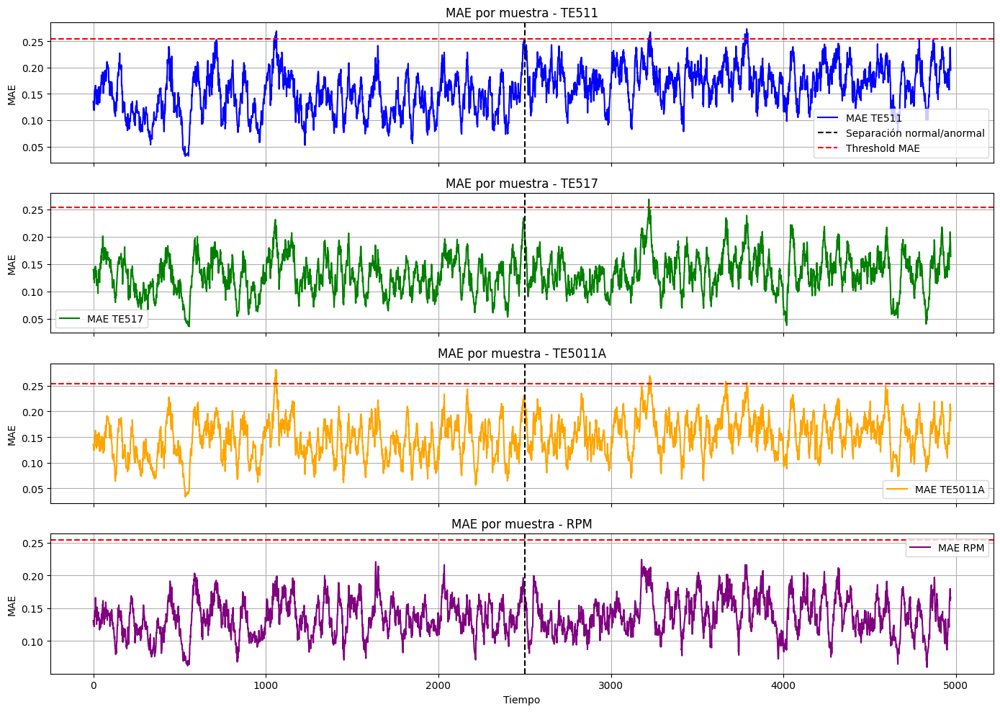

In [ ]:
# MAE por muestra y por variable (shape: [n_muestras, n_variables])
mae_gases_mixto = np.mean(np.abs(X_gases_mixto_pred - X_gases_mixto), axis=1)
import matplotlib.pyplot as plt

fig, axs = plt.subplots(4, 1, figsize=(14, 10), sharex=True)

# === MAE para TE511
axs[0].plot(mae_gases_mixto[:, 0], label='MAE TE511', color='blue')
axs[0].axvline(x=2500, color='black', linestyle='--', label='Separación normal/anormal')
axs[0].axhline(y=threshold_gases, color='red', linestyle='--', label='Threshold MAE')
axs[0].set_title('MAE por muestra - TE511')
axs[0].set_ylabel('MAE')
axs[0].legend()
axs[0].grid(True)

# === MAE para TE517
axs[1].plot(mae_gases_mixto[:, 1], label='MAE TE517', color='green')
axs[1].axvline(x=2500, color='black', linestyle='--')
axs[1].axhline(y=threshold_gases, color='red', linestyle='--')
axs[1].set_title('MAE por muestra - TE517')
axs[1].set_ylabel('MAE')
axs[1].legend()
axs[1].grid(True)

# === MAE para TE5011A
axs[2].plot(mae_gases_mixto[:, 2], label='MAE TE5011A', color='orange')
axs[2].axvline(x=2500, color='black', linestyle='--')
axs[2].axhline(y=threshold_gases, color='red', linestyle='--')
axs[2].set_title('MAE por muestra - TE5011A')
axs[2].set_ylabel('MAE')
axs[2].legend()
axs[2].grid(True)

# === MAE para RPM
axs[3].plot(mae_gases_mixto[:, 3], label='MAE RPM', color='purple')
axs[3].axvline(x=2500, color='black', linestyle='--')
axs[3].axhline(y=threshold_gases, color='red', linestyle='--')
axs[3].set_title('MAE por muestra - RPM')
axs[3].set_ylabel('MAE')
axs[3].set_xlabel('Tiempo')
axs[3].legend()
axs[3].grid(True)

plt.tight_layout()
plt.show()


# SUBSISTEMA DE LUBRICANTE


In [ ]:
# === Parámetros ===
time_steps = 30
variables_lubricante = ['RPM', 'TE201', 'TE202', 'TE272', 'PDT243', 'PT271', 'XX001', 'XX002', 'XX012']
# === Extraer vectores multivariables para el sistema de lubricante ===
vector_lubricante_vae = np.stack(
    [vectores_por_variable_vae[var] for var in variables_lubricante],
    axis=1
)

# === Escalado multivariable del sistema de lubricante ===
scaler_lubricante_vae = MinMaxScaler()
vector_lubricante_vae_scaled = scaler_lubricante_vae.fit_transform(vector_lubricante_vae)

# === Crear secuencias para el sistema de lubricante ===
def create_sequences(data, time_steps=30):
    sequences = []
    for i in range(len(data) - time_steps):
        sequences.append(data[i:i + time_steps])
    return np.array(sequences)

X_lubricante_vae = create_sequences(vector_lubricante_vae_scaled, time_steps)


In [ ]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dropout, RepeatVector, TimeDistributed, Dense

# === Fijar semillas para reproducibilidad ===
np.random.seed(42)
tf.random.set_seed(42)

print(f"Forma de las secuencias del sistema de lubricante: {X_lubricante_vae.shape}")  # (n_muestras, time_steps, n_variables)

# === Construcción del modelo LSTM Autoencoder para el sistema de lubricante ===
n_features_lubricante = X_lubricante_vae.shape[2]

modelo_lubricante_lstm_vae = Sequential([
    LSTM(128, activation='tanh', input_shape=(time_steps, n_features_lubricante), return_sequences=False),
    Dropout(0.2),
    RepeatVector(time_steps),
    LSTM(128, activation='tanh', return_sequences=True),
    Dropout(0.2),
    TimeDistributed(Dense(n_features_lubricante))
])

modelo_lubricante_lstm_vae.compile(optimizer='adam', loss='mse')

# === Entrenamiento del modelo para el sistema de lubricante ===
historial_lubricante_lstm_vae = modelo_lubricante_lstm_vae.fit(
    X_lubricante_vae, X_lubricante_vae,
    epochs=50,
    batch_size=32,
    validation_split=0.1,
    shuffle=False,
    verbose=1
)


Forma de las secuencias del sistema de lubricante: (4970, 30, 9)
Epoch 1/50


/usr/local/lib/python3.11/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


140/140 ━━━━━━━━━━━━━━━━━━━━ 20s 106ms/step - loss: 0.0986 - val_loss: 0.0203
Epoch 2/50
140/140 ━━━━━━━━━━━━━━━━━━━━ 20s 105ms/step - loss: 0.0275 - val_loss: 0.0199
Epoch 3/50
140/140 ━━━━━━━━━━━━━━━━━━━━ 20s 102ms/step - loss: 0.0253 - val_loss: 0.0198
Epoch 4/50
140/140 ━━━━━━━━━━━━━━━━━━━━ 21s 103ms/step - loss: 0.0244 - val_loss: 0.0198
Epoch 5/50
140/140 ━━━━━━━━━━━━━━━━━━━━ 20s 102ms/step - loss: 0.0239 - val_loss: 0.0198
Epoch 6/50
140/140 ━━━━━━━━━━━━━━━━━━━━ 21s 103ms/step - loss: 0.0235 - val_loss: 0.0197
Epoch 7/50
140/140 ━━━━━━━━━━━━━━━━━━━━ 20s 102ms/step - loss: 0.0232 - val_loss: 0.0197
Epoch 8/50
140/140 ━━━━━━━━━━━━━━━━━━━━ 20s 101ms/step - loss: 0.0229 - val_loss: 0.0197
Epoch 9/50
140/140 ━━━━━━━━━━━━━━━━━━━━ 21s 104ms/step - loss: 0.0227 - val_loss: 0.0197
Epoch 10/50
140/140 ━━━━━━━━━━━━━━━━━━━━ 14s 101ms/step - loss: 0.0226 - val_loss: 0.0196
Epoch 11/50
140/140 ━━━━━━━━━━━━━━━━━━━━ 21s 103ms/step - loss: 0.0224 - val_loss: 0.0196
Epoch 12/50
140/140 ━━━━━━━━━━

In [ ]:
import joblib
import json
from tensorflow.keras.models import load_model

# === Guardar el scaler ===
joblib.dump(scaler_lubricante_vae, 'scaler_lstm_vae_lubricante.pkl')

# === Guardar el modelo ===
modelo_lubricante_lstm_vae.save('modelo_lstm_vae_lubricante.h5')

In [ ]:
import joblib
from tensorflow.keras.models import load_model

# === Cargar el scaler ===
scaler_lubricante_vae = joblib.load('scaler_lstm_vae_lubricante.pkl')

# === Cargar el modelo sin compilar ===
modelo_lubricante_lstm_vae = load_model('modelo_lstm_vae_lubricante.h5', compile=False)


In [ ]:
# === Predicción sobre los datos de entrenamiento del sistema de lubricante ===
X_lubricante_vae_pred = modelo_lubricante_lstm_vae.predict(X_lubricante_vae)

# === Cálculo del MAE por muestra (promediando todas las variables y pasos temporales) ===
mae_lubricante_por_muestra = np.mean(np.abs(X_lubricante_vae_pred - X_lubricante_vae), axis=(1, 2))

# === Threshold como el MAE máximo observado en entrenamiento ===
threshold_mae_lubricante = np.max(mae_lubricante_por_muestra)
print(f"Threshold de MAE para sistema de lubricante: {threshold_mae_lubricante:.4f}")


156/156 ━━━━━━━━━━━━━━━━━━━━ 12s 76ms/step
Threshold de MAE para sistema de lubricante: 1.0000


In [ ]:
# === 1. Construir el vector multivariable anormal desde el diccionario
variables_lubricante = ['RPM', 'TE201', 'TE202', 'TE272', 'PDT243', 'PT271', 'XX001', 'XX002', 'XX012']
vector_lubricante_anormal = np.stack([
    vectores_anormales_vae[var] for var in variables_lubricante
], axis=1)  # (n_muestras, n_variables)

# === 2. Escalar con el mismo scaler usado en entrenamiento
vector_lubricante_anormal_scaled = scaler_lubricante_vae.transform(vector_lubricante_anormal)

# === 3. Crear secuencias para los datos anormales del sistema de lubricante
X_lubricante_anormal = create_sequences(vector_lubricante_anormal_scaled, time_steps)

# === 4. Hacer predicciones y calcular el MAE por muestra
X_lubricante_anormal_pred = modelo_lubricante_lstm_vae.predict(X_lubricante_anormal)
mae_lubricante_anormal = np.mean(np.abs(X_lubricante_anormal_pred - X_lubricante_anormal), axis=(1, 2))

# === 5. Comparar con el threshold para marcar anomalías
flags_anomalias_lubricante = mae_lubricante_anormal > threshold_mae_lubricante
indices_anomalos_lubricante = np.where(flags_anomalias_lubricante)[0] + time_steps  # Ajustar índices al vector original

# === 6. Mostrar resumen
print(f"Se detectaron {np.sum(flags_anomalias_lubricante)} anomalías de {len(mae_lubricante_anormal)} muestras en el sistema de lubricante")
# === 7. Calcular Silhouette Score si hay al menos dos clases
labels_lubricante = flags_anomalias_lubricante.astype(int)
X_silhouette_lubricante = mae_lubricante_anormal.reshape(-1, 1)

if len(np.unique(labels_lubricante)) < 2:
    print("No se puede calcular Silhouette Score: todas las muestras tienen la misma etiqueta.")
else:
    score_lubricante = silhouette_score(X_silhouette_lubricante, labels_lubricante)
    print(f"Silhouette Score (sistema de lubricante): {score_lubricante:.4f}")



156/156 ━━━━━━━━━━━━━━━━━━━━ 5s 32ms/step
Se detectaron 3855 anomalías de 4970 muestras en el sistema de lubricante
Silhouette Score (sistema de lubricante): 0.5533


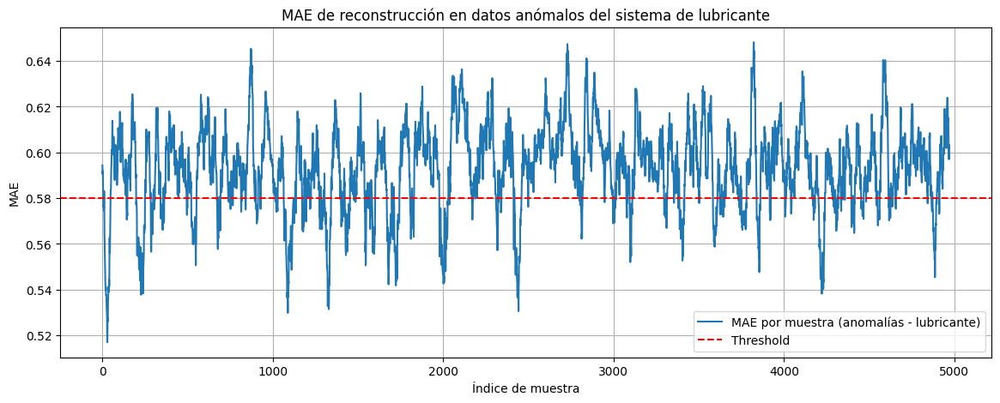

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))
plt.plot(mae_lubricante_anormal, label='MAE por muestra (anomalías - lubricante)')
plt.axhline(threshold_mae_lubricante, color='red', linestyle='--', label='Threshold')
plt.title('MAE de reconstrucción en datos anómalos del sistema de lubricante')
plt.xlabel('Índice de muestra')
plt.ylabel('MAE')
plt.legend()
plt.grid(True)
plt.show()


In [ ]:
# === Concatenar datos normales y anómalos por variable del sistema de lubricante ===
vectores_lubricante_mixto = [
    np.concatenate([
        vectores_por_variable_vae[var][:2500],
        vectores_anormales_vae[var][:2500]
    ]) for var in variables_lubricante
]

# === Combinar en array multivariable ===
vector_lubricante_mixto = np.stack(vectores_lubricante_mixto, axis=1)  # (5000, 10)

# === Escalado con el scaler entrenado del sistema de lubricante
vector_lubricante_mixto_scaled = scaler_lubricante_vae.transform(vector_lubricante_mixto)

# === Crear secuencias
X_lubricante_mixto = create_sequences(vector_lubricante_mixto_scaled, time_steps)

# === Predicción con el modelo entrenado
X_lubricante_mixto_pred = modelo_lubricante_lstm_vae.predict(X_lubricante_mixto)

# === Cálculo del MAE por muestra
mae_lubricante_mixto = np.mean(np.abs(X_lubricante_mixto_pred - X_lubricante_mixto), axis=(1, 2))

# === Detectar anomalías
flags_anomalias_lubricante_mixto = mae_lubricante_mixto > threshold_mae_lubricante
indices_anomalos_lubricante_mixto = np.where(flags_anomalias_lubricante_mixto)[0] + time_steps

# === Imprimir resumen
print(f"Anomalías detectadas en el sistema de lubricante: {np.sum(flags_anomalias_lubricante_mixto)} de {len(mae_lubricante_mixto)} muestras")


156/156 ━━━━━━━━━━━━━━━━━━━━ 5s 34ms/step
Anomalías detectadas en el sistema de lubricante: 1504 de 4970 muestras


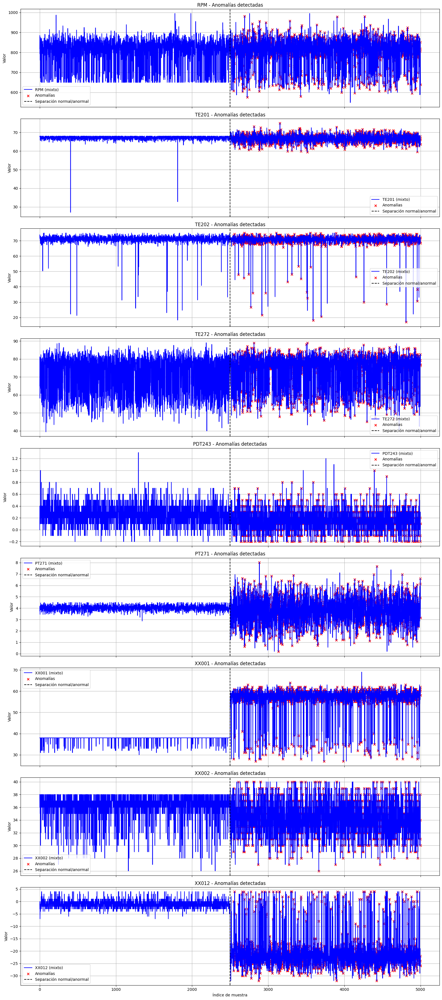

In [ ]:
import matplotlib.pyplot as plt

# === Configurar subplots: uno debajo del otro ===
n_vars = len(variables_lubricante)
fig, axs = plt.subplots(n_vars, 1, figsize=(16, 4 * n_vars), sharex=True)
axs = axs if isinstance(axs, np.ndarray) else [axs]  # Asegura que axs sea iterable

for i, var in enumerate(variables_lubricante):
    # Reconstrucción del vector mixto para la variable
    vector_mixto = np.concatenate([
        vectores_por_variable_vae[var][:2500],
        vectores_anormales_vae[var][:2500]
    ])

    # Dibujar
    axs[i].plot(vector_mixto, label=f'{var} (mixto)', color='blue')
    axs[i].scatter(indices_anomalos_lubricante_mixto, vector_mixto[indices_anomalos_lubricante_mixto],
                   color='red', marker='x', s=30, label='Anomalías')
    axs[i].axvline(x=2500, color='black', linestyle='--', label='Separación normal/anormal')
    axs[i].set_title(f'{var} - Anomalías detectadas')
    axs[i].set_ylabel('Valor')
    axs[i].legend()
    axs[i].grid(True)

plt.xlabel('Índice de muestra')
plt.tight_layout()
plt.show()


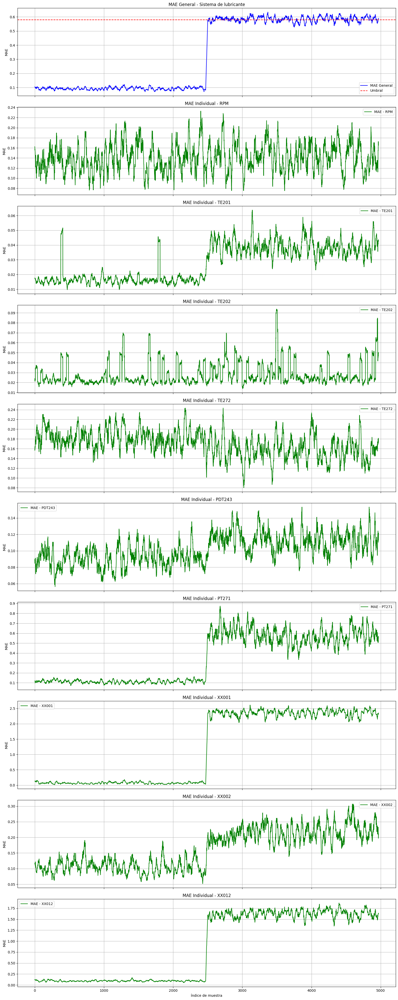

In [ ]:
import matplotlib.pyplot as plt
# === MAE por variable ===
# Dimensión (n_muestras, n_variables)
mae_por_variable = np.mean(
    np.abs(X_lubricante_mixto_pred - X_lubricante_mixto),
    axis=1  # promedio sobre pasos temporales
)
n_vars = len(variables_lubricante)
fig, axs = plt.subplots(n_vars + 1, 1, figsize=(16, 4 * (n_vars + 1)), sharex=True)

# === Gráfica 1: MAE general ===
axs[0].plot(mae_lubricante_mixto, label='MAE General', color='blue')
axs[0].axhline(y=threshold_mae_lubricante, color='red', linestyle='--', label='Umbral')
axs[0].set_title('MAE General - Sistema de lubricante')
axs[0].set_ylabel('MAE')
axs[0].legend()
axs[0].grid(True)

# === Gráficas 2 a N+1: MAE individual por variable ===
for i, var in enumerate(variables_lubricante):
    axs[i + 1].plot(mae_por_variable[:, i], label=f'MAE - {var}', color='green')
    axs[i + 1].set_title(f'MAE Individual - {var}')
    axs[i + 1].set_ylabel('MAE')
    axs[i + 1].legend()
    axs[i + 1].grid(True)

# Etiqueta común para el eje X
axs[-1].set_xlabel('Índice de muestra')

plt.tight_layout()
plt.show()



  # SUBSISTEMA DE REFRIGERACIÓN

In [ ]:
# === Parámetros ===
time_steps = 30
variables_sistema_refrigeracion = ['PT401', 'TE401', 'PT471', 'TE600 - Carga', 'TE600 - Aire entrada al turbo']

# === Extraer vectores para las variables del sistema de refrigeración ===
vector_multivariable_refrigeracion = np.stack(
    [vectores_por_variable_vae[var] for var in variables_sistema_refrigeracion],
    axis=1
)

# === Escalado multivariable ===
scaler_refrigeracion = MinMaxScaler()
scaled_vector_refrigeracion = scaler_refrigeracion.fit_transform(vector_multivariable_refrigeracion)

# === Crear secuencias ===
def create_sequences(data, time_steps=30):
    sequences = []
    for i in range(len(data) - time_steps):
        sequences.append(data[i:i + time_steps])
    return np.array(sequences)

X_lstm_vae_refrigeracion = create_sequences(scaled_vector_refrigeracion, time_steps)


In [ ]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dropout, RepeatVector, TimeDistributed, Dense

# === Fijar semillas para reproducibilidad ===
np.random.seed(42)
tf.random.set_seed(42)

print(f"Forma de las secuencias (sistema de refrigeración): {X_lstm_vae_refrigeracion.shape}")  # (n_muestras, time_steps, n_variables)

# === Construcción del modelo LSTM Autoencoder para el sistema de refrigeración ===
n_features_refrigeracion = X_lstm_vae_refrigeracion.shape[2]

model_lstm_vae_refrigeracion = Sequential([
    LSTM(128, activation='tanh', input_shape=(time_steps, n_features_refrigeracion), return_sequences=False),
    Dropout(0.2),
    RepeatVector(time_steps),
    LSTM(128, activation='tanh', return_sequences=True),
    Dropout(0.2),
    TimeDistributed(Dense(n_features_refrigeracion))
])

model_lstm_vae_refrigeracion.compile(optimizer='adam', loss='mse')

# === Entrenamiento ===
history_lstm_vae_refrigeracion = model_lstm_vae_refrigeracion.fit(
    X_lstm_vae_refrigeracion, X_lstm_vae_refrigeracion,
    epochs=50,
    batch_size=32,
    validation_split=0.1,
    shuffle=False,
    verbose=1
)


Forma de las secuencias (sistema de refrigeración): (4970, 30, 5)
Epoch 1/50


/usr/local/lib/python3.11/dist-packages/keras/src/layers/rnn/rnn.py:200: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


140/140 ━━━━━━━━━━━━━━━━━━━━ 23s 127ms/step - loss: 0.1167 - val_loss: 0.0290
Epoch 2/50
140/140 ━━━━━━━━━━━━━━━━━━━━ 18s 112ms/step - loss: 0.0328 - val_loss: 0.0282
Epoch 3/50
140/140 ━━━━━━━━━━━━━━━━━━━━ 20s 110ms/step - loss: 0.0304 - val_loss: 0.0278
Epoch 4/50
140/140 ━━━━━━━━━━━━━━━━━━━━ 20s 110ms/step - loss: 0.0296 - val_loss: 0.0279
Epoch 5/50
140/140 ━━━━━━━━━━━━━━━━━━━━ 20s 109ms/step - loss: 0.0292 - val_loss: 0.0280
Epoch 6/50
140/140 ━━━━━━━━━━━━━━━━━━━━ 22s 124ms/step - loss: 0.0287 - val_loss: 0.0279
Epoch 7/50
140/140 ━━━━━━━━━━━━━━━━━━━━ 19s 111ms/step - loss: 0.0285 - val_loss: 0.0280
Epoch 8/50
140/140 ━━━━━━━━━━━━━━━━━━━━ 21s 112ms/step - loss: 0.0283 - val_loss: 0.0279
Epoch 9/50
140/140 ━━━━━━━━━━━━━━━━━━━━ 20s 109ms/step - loss: 0.0281 - val_loss: 0.0279
Epoch 10/50
140/140 ━━━━━━━━━━━━━━━━━━━━ 21s 111ms/step - loss: 0.0280 - val_loss: 0.0279
Epoch 11/50
140/140 ━━━━━━━━━━━━━━━━━━━━ 22s 120ms/step - loss: 0.0278 - val_loss: 0.0279
Epoch 12/50
140/140 ━━━━━━━━━━

In [ ]:
import joblib
import json
from tensorflow.keras.models import load_model

# === Guardar el scaler ===
joblib.dump(scaler_refrigeracion, 'scaler_lstm_vae_refrigeracion.pkl')

# === Guardar el modelo ===
model_lstm_vae_refrigeracion.save('modelo_lstm_vae_refrigeracion.h5')

In [ ]:
import joblib
from tensorflow.keras.models import load_model

# === Cargar el scaler ===
scaler_refrigeracion = joblib.load('scaler_lstm_vae_refrigeracion.pkl')

# === Cargar el modelo sin compilar ===
model_lstm_vae_refrigeracion = load_model('modelo_lstm_vae_refrigeracion.h5', compile=False)


In [ ]:
# === Predicción sobre los datos de entrenamiento (sistema de refrigeración) ===
X_lstm_vae_refrigeracion_pred = model_lstm_vae_refrigeracion.predict(X_lstm_vae_refrigeracion)

# === Cálculo del MAE por muestra (promediando todas las variables y pasos temporales) ===
mae_por_muestra_refrigeracion = np.mean(
    np.abs(X_lstm_vae_refrigeracion_pred - X_lstm_vae_refrigeracion),
    axis=(1, 2)
)

# === Threshold como el MAE máximo observado en entrenamiento ===
threshold_mae_refrigeracion = np.max(mae_por_muestra_refrigeracion)
print(f"Threshold de MAE (sistema de refrigeración): {threshold_mae_refrigeracion:.4f}")


156/156 ━━━━━━━━━━━━━━━━━━━━ 6s 32ms/step
Threshold de MAE (sistema de refrigeración): 0.2500


In [ ]:
# === 1. Construir el vector multivariable anormal del sistema de refrigeración ===
vector_multivariable_anormal_refrigeracion = np.stack([
    vectores_anormales_vae[var] for var in variables_sistema_refrigeracion
], axis=1)  # (n_muestras, n_variables)

# === 2. Escalar con el mismo scaler que se usó para entrenar
scaled_anormal_refrigeracion = scaler_refrigeracion.transform(vector_multivariable_anormal_refrigeracion)

# === 3. Crear secuencias
X_anormal_refrigeracion = create_sequences(scaled_anormal_refrigeracion, time_steps)

# === 4. Hacer predicciones y calcular el MAE por muestra
X_anormal_refrigeracion_pred = model_lstm_vae_refrigeracion.predict(X_anormal_refrigeracion)
mae_anormal_refrigeracion = np.mean(
    np.abs(X_anormal_refrigeracion_pred - X_anormal_refrigeracion),
    axis=(1, 2)
)

# === 5. Comparar con el threshold
anomaly_flags_refrigeracion = mae_anormal_refrigeracion > threshold_mae_refrigeracion
anomaly_indices_refrigeracion = np.where(anomaly_flags_refrigeracion)[0] + time_steps  # Ajustar índices

# === 6. Mostrar resumen
print(f"Se detectaron {np.sum(anomaly_flags_refrigeracion)} anomalías de {len(mae_anormal_refrigeracion)} muestras (sistema de refrigeración)")

# === 7. Calcular Silhouette Score si hay al menos dos clases
labels_refrigeracion = anomaly_flags_refrigeracion.astype(int)
X_silhouette_refrigeracion = mae_anormal_refrigeracion.reshape(-1, 1)

if len(np.unique(labels_refrigeracion)) < 2:
    print("No se puede calcular Silhouette Score: todas las muestras tienen la misma etiqueta.")
else:
    score_refrigeracion = silhouette_score(X_silhouette_refrigeracion, labels_refrigeracion)
    print(f"Silhouette Score (sistema de refrigeración): {score_refrigeracion:.4f}")



156/156 ━━━━━━━━━━━━━━━━━━━━ 4s 26ms/step
Se detectaron 2504 anomalías de 4970 muestras (sistema de refrigeración)
Silhouette Score (sistema de refrigeración): 0.5564


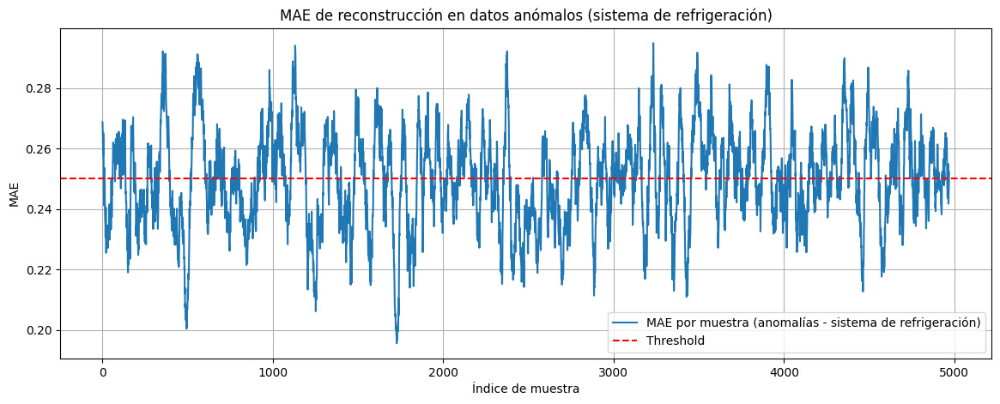

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))
plt.plot(mae_anormal_refrigeracion, label='MAE por muestra (anomalías - sistema de refrigeración)')
plt.axhline(threshold_mae_refrigeracion, color='red', linestyle='--', label='Threshold')
plt.title('MAE de reconstrucción en datos anómalos (sistema de refrigeración)')
plt.xlabel('Índice de muestra')
plt.ylabel('MAE')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
# === Concatenar datos normales y anómalos por variable del sistema de refrigeración ===
vectores_refrigeracion_mixtos = [
    np.concatenate([
        vectores_por_variable_vae[var][:2500],
        vectores_anormales_vae[var][:2500]
    ]) for var in variables_sistema_refrigeracion
]

# === Combinar en array multivariable ===
vector_multivariable_mixto_refrigeracion = np.stack(vectores_refrigeracion_mixtos, axis=1)  # (5000, 6)

# === Escalado con el scaler entrenado
scaled_mixto_refrigeracion = scaler_refrigeracion.transform(vector_multivariable_mixto_refrigeracion)

# === Crear secuencias
X_mixto_refrigeracion = create_sequences(scaled_mixto_refrigeracion, time_steps)

# === Predicción
X_mixto_refrigeracion_pred = model_lstm_vae_refrigeracion.predict(X_mixto_refrigeracion)

# === Cálculo de MAE
mae_mixto_refrigeracion = np.mean(
    np.abs(X_mixto_refrigeracion_pred - X_mixto_refrigeracion),
    axis=(1, 2)
)

# === Detectar anomalías
anomaly_flags_mixto_refrigeracion = mae_mixto_refrigeracion > threshold_mae_refrigeracion
anomaly_indices_mixto_refrigeracion = np.where(anomaly_flags_mixto_refrigeracion)[0] + time_steps

print(f"Anomalías detectadas (sistema de refrigeración): {np.sum(anomaly_flags_mixto_refrigeracion)} de {len(mae_mixto_refrigeracion)} muestras")


156/156 ━━━━━━━━━━━━━━━━━━━━ 4s 24ms/step
Anomalías detectadas (sistema de refrigeración): 1184 de 4970 muestras


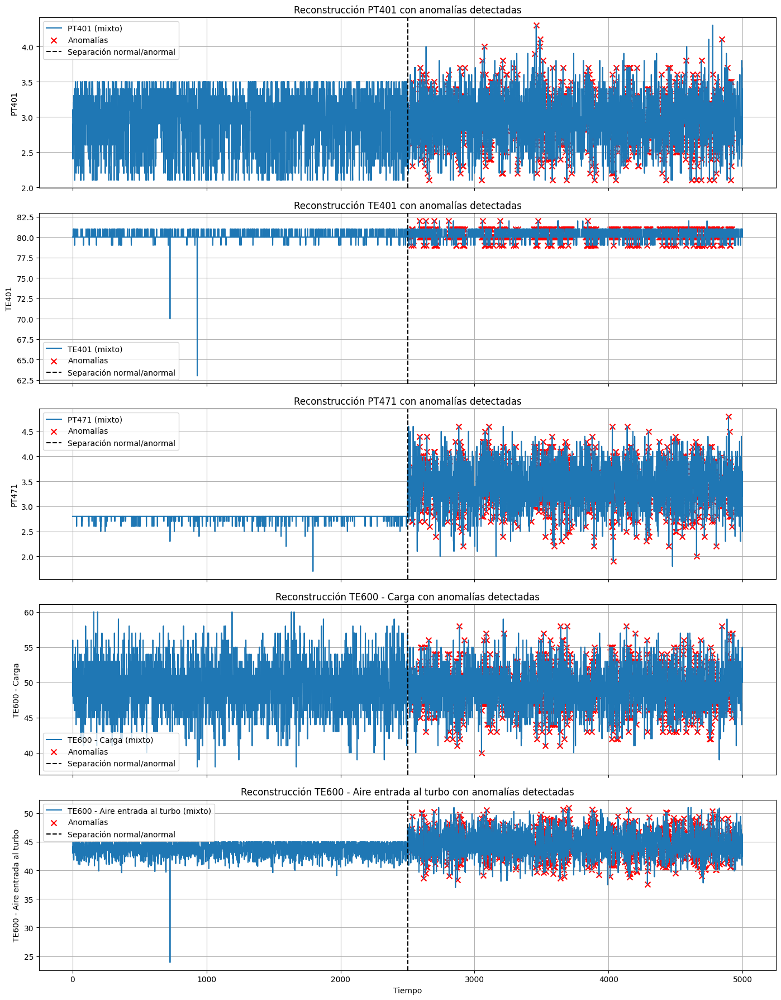

In [ ]:
import matplotlib.pyplot as plt

# === Crear figura con 6 subplots, uno por variable ===
fig, axs = plt.subplots(len(variables_sistema_refrigeracion), 1, figsize=(14, 18), sharex=True)

# === Graficar cada variable del sistema de refrigeración ===
for i, var in enumerate(variables_sistema_refrigeracion):
    vector_mixto = vectores_refrigeracion_mixtos[i]
    axs[i].plot(vector_mixto, label=f'{var} (mixto)', color='tab:blue')
    axs[i].scatter(anomaly_indices_mixto_refrigeracion, vector_mixto[anomaly_indices_mixto_refrigeracion],
                   color='red', marker='x', s=50, label='Anomalías')
    axs[i].axvline(x=2500, color='black', linestyle='--', label='Separación normal/anormal')
    axs[i].set_ylabel(f'{var}')
    axs[i].set_title(f'Reconstrucción {var} con anomalías detectadas')
    axs[i].legend()
    axs[i].grid(True)

# === Ajustes finales ===
plt.xlabel('Tiempo')
plt.tight_layout()
plt.show()


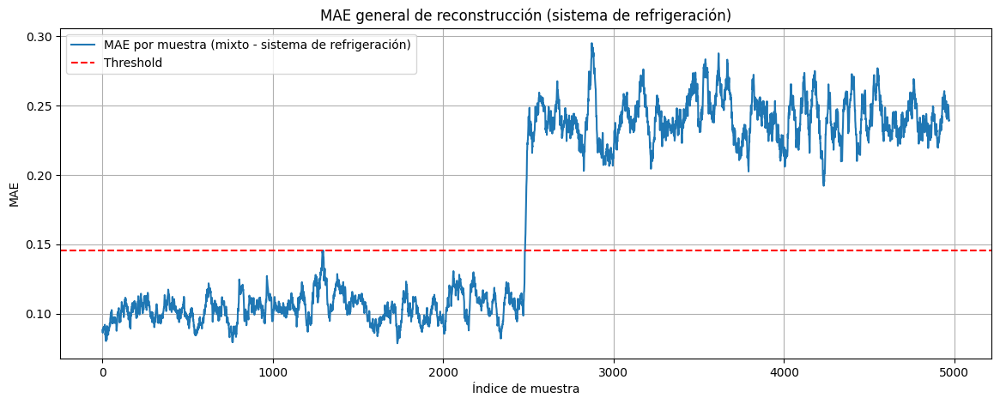

In [ ]:
plt.figure(figsize=(14, 5))
plt.plot(mae_mixto_refrigeracion, label='MAE por muestra (mixto - sistema de refrigeración)')
plt.axhline(threshold_mae_refrigeracion, color='red', linestyle='--', label='Threshold')
plt.title('MAE general de reconstrucción (sistema de refrigeración)')
plt.xlabel('Índice de muestra')
plt.ylabel('MAE')
plt.legend()
plt.grid(True)
plt.show()


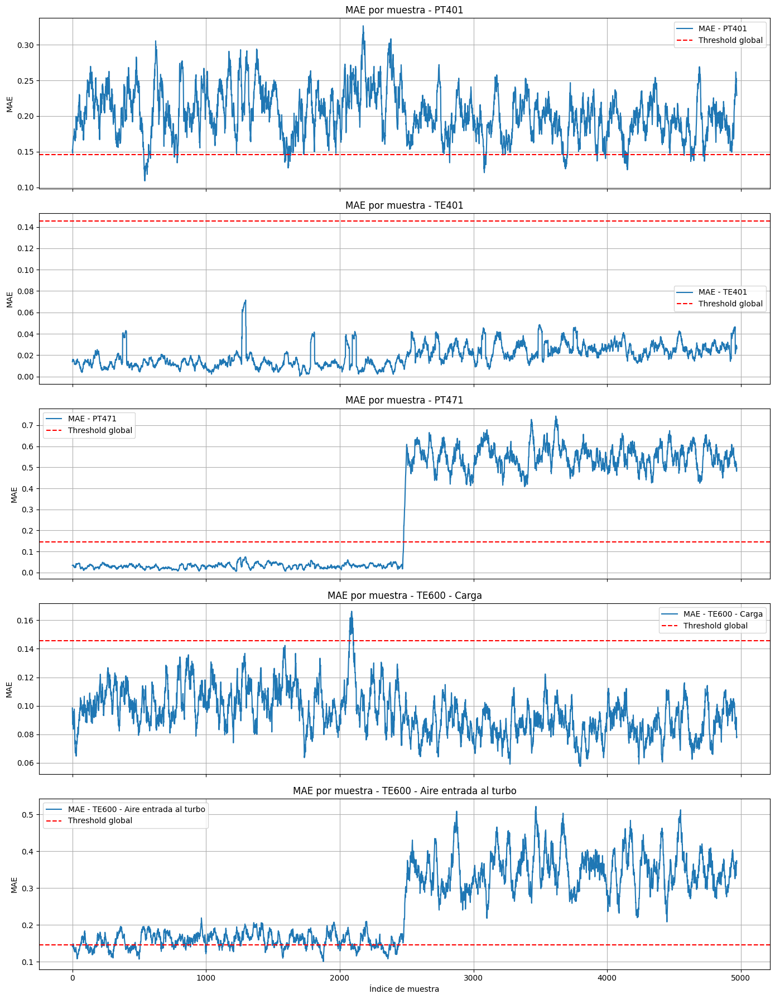

In [ ]:
# === Calcular el error absoluto por muestra, paso temporal y variable
errores_mixtos = np.abs(X_mixto_refrigeracion_pred - X_mixto_refrigeracion)  # shape: (n_samples, time_steps, n_variables)

# === Promediar por eje temporal para obtener MAE por muestra y variable
mae_por_variable = np.mean(errores_mixtos, axis=1)  # shape: (n_samples, n_variables)
import matplotlib.pyplot as plt

fig, axs = plt.subplots(len(variables_sistema_refrigeracion), 1, figsize=(14, 18), sharex=True)

for i, var in enumerate(variables_sistema_refrigeracion):
    axs[i].plot(mae_por_variable[:, i], label=f'MAE - {var}', color='tab:blue')
    axs[i].axhline(threshold_mae_refrigeracion, color='red', linestyle='--', label='Threshold global')
    axs[i].set_title(f'MAE por muestra - {var}')
    axs[i].set_ylabel('MAE')
    axs[i].legend()
    axs[i].grid(True)

plt.xlabel('Índice de muestra')
plt.tight_layout()
plt.show()



#DATOS NUEVOS

##NUEVOS MODELOS

In [13]:
import json
import pandas as pd
from openpyxl import load_workbook

# --- Cargar el JSON ---
with open("resultados.json", "r", encoding="utf-8") as f:
    datos = json.load(f)

# --- Definir los subsistemas ---
subsistemas = {
    "FUEL SYSTEM": ["PT101", "TE101"],
    "LUBRICACION": ["TE272","PT201","TE201","PDT243","TE202","PT271"],
    "COOLING": ["TE401","TE402","TE471"],
    "GASES DE ESCAPE": ["TE5011A","TE5021A","TE5031A","TE5041A","TE5051A","TE5061A"],
    "BEARING": ["TE700","TE701","TE702","TE703","TE704","TE705"],
    "CHARGE AIR": ["PT601","TE601","TE600"],
    "OTHER": ["PT301","PT311"]
}

# --- Nombres formales ---
nombres_formales_2 = {
    'RPM': 'Engine speed [RPM]',
    'PT401': 'HT inlet pressure (PT401) [bar]',
    'TE401': 'HT inlet temperature (TE401) [°C]',
    'TE402': 'HT outlet temperature (TE402) [°C]',
    'PT471': 'LT inlet pressure (PT471) [bar]',
    'TE471': 'LT inlet temperature (TE471) [°C]',
    'TE600 - Carga': 'Charge air temperature (TE600) [°C]',
    'TE600 - Aire entrada al turbo': 'Turbo inlet air temperature (TE600) [°C]',
    'PT101': 'Engine F.O. inlet pressure (PT101) [bar]',
    'TE101': 'Engine F.O. inlet temperature (TE101) [°C]',
    'PT201': 'Engine L.O. inlet pressure (PT201) [bar]',
    'TE201': 'Engine L.O. inlet temperature (TE201) [°C]',
    'TE202': 'Engine L.O. outlet temperature (TE202) [°C]',
    'TE272': 'Turbo L.O. outlet temperature (TE272) [°C]',
    'PDT243': 'Oil filter differential pressure (PDT243) [bar]',
    'PT271': 'Turbo L.O. inlet pressure (PT271) [bar]',
    'XX001': 'Fresh water inlet temperature (XX001) [°C]',
    'XX002': 'Fresh water outlet temperature (XX002) [°C]',
    'XX012': 'Fresh water temperature difference (XX002 - XX001) [°C]',
    'TE511': 'Exhaust gas turbo inlet temperature (TE511) [°C]',
    'TE517': 'Exhaust gas turbo outlet temperature (TE517) [°C]',
    'TE5011A': 'Maximum cylinder temperature (TE5011A) [°C]'
}

# --- Construir la tabla ---
filas = []
for subsistema, variables in subsistemas.items():
    for var in variables:
        if var in datos:
            nombre = nombres_formales_2.get(var, datos[var].get("Nombre", ""))
            fila = {
                "Subsistema": subsistema,
                "Variable": var,
                "Nombre": nombre,
                "Valor mínimo": datos[var].get("Valor mínimo") or datos[var].get("Valor m\u00ednimo"),
                "Valor nominal": datos[var].get("Valor nominal"),
                "Valor máximo": datos[var].get("Valor máximo") or datos[var].get("Valor m\u00e1ximo")
            }
            filas.append(fila)

# --- Crear DataFrame ---
df = pd.DataFrame(filas)

# --- Exportar a Excel ---
nombre_archivo = "subsistemas_rangos_anidado.xlsx"
df.to_excel(nombre_archivo, index=False)

# --- Abrir Excel para fusionar celdas por subsistema ---
wb = load_workbook(nombre_archivo)
ws = wb.active

col_subsistema = 1  # columna A
row = 2  # empezar desde la fila 2 porque fila 1 es header
while row <= ws.max_row:
    subs_actual = ws.cell(row=row, column=col_subsistema).value
    start_row = row
    # buscar cuántas filas consecutivas tienen el mismo subsistema
    while row <= ws.max_row and ws.cell(row=row, column=col_subsistema).value == subs_actual:
        row += 1
    end_row = row - 1
    if end_row > start_row:
        ws.merge_cells(start_row=start_row, start_column=col_subsistema,
                       end_row=end_row, end_column=col_subsistema)

wb.save(nombre_archivo)
print(f"Archivo '{nombre_archivo}' creado con tabla jerárquica y nombres formales.")



Archivo 'subsistemas_rangos_anidado.xlsx' creado con tabla jerárquica y nombres formales.


Filas originales: 5000, filas sin vacíos: 5000


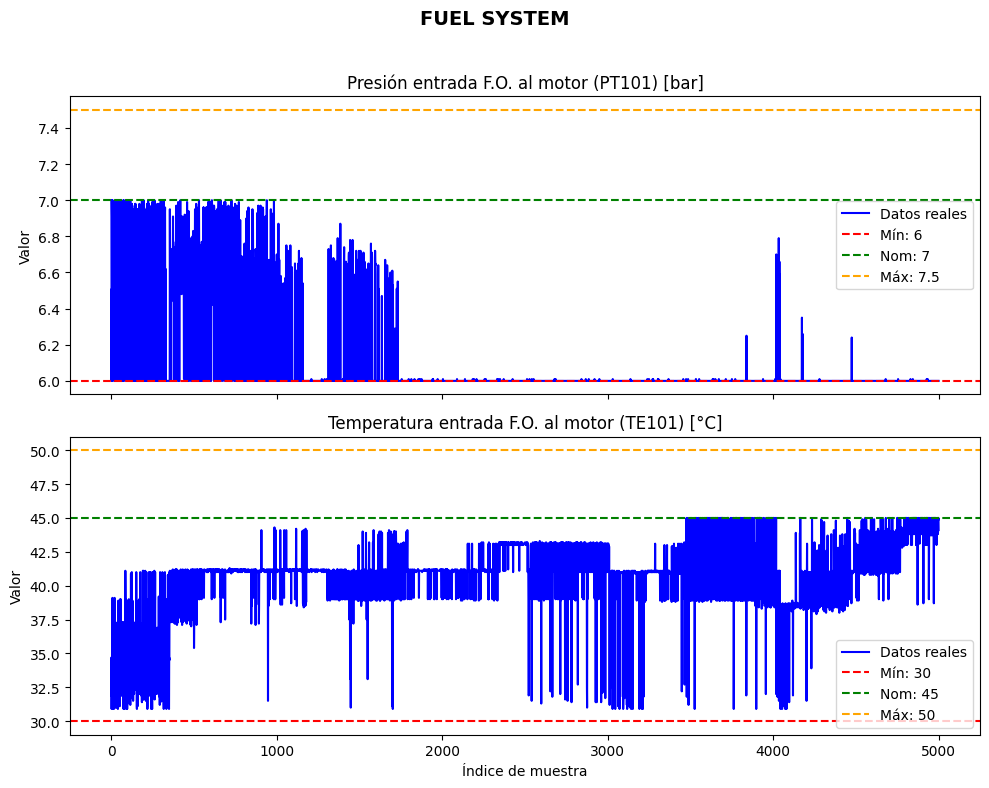

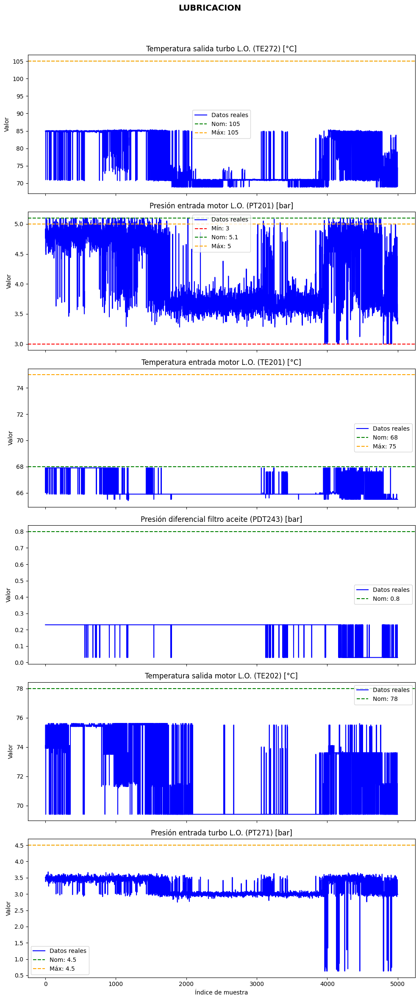

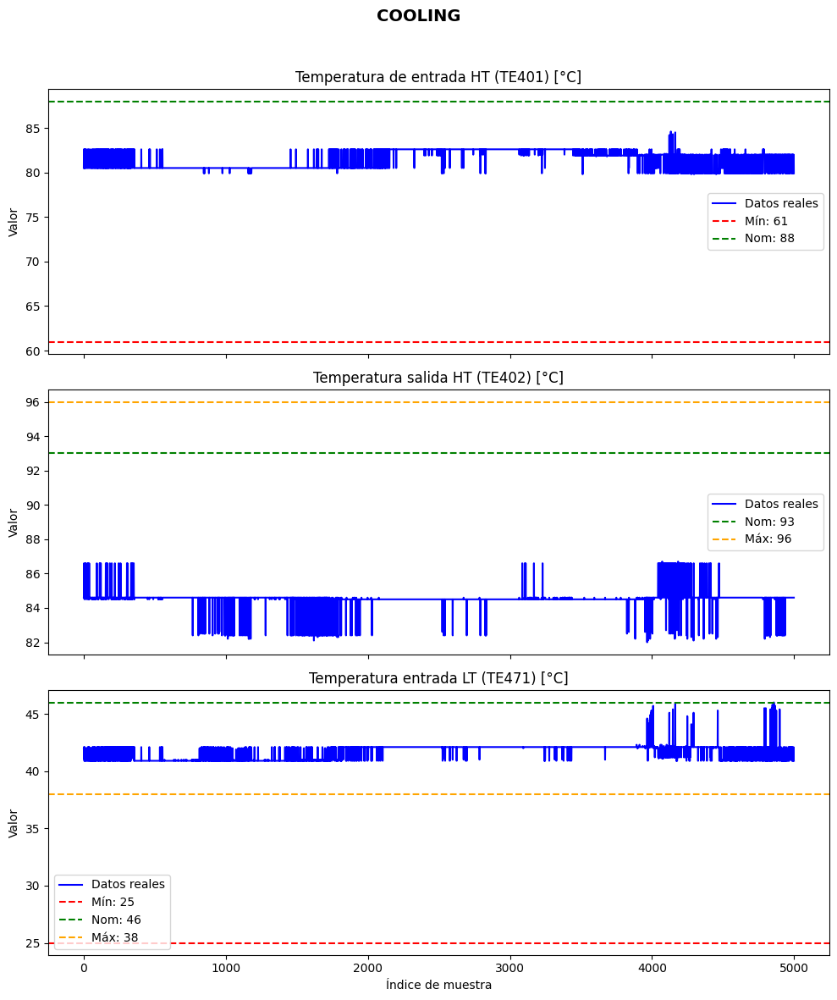

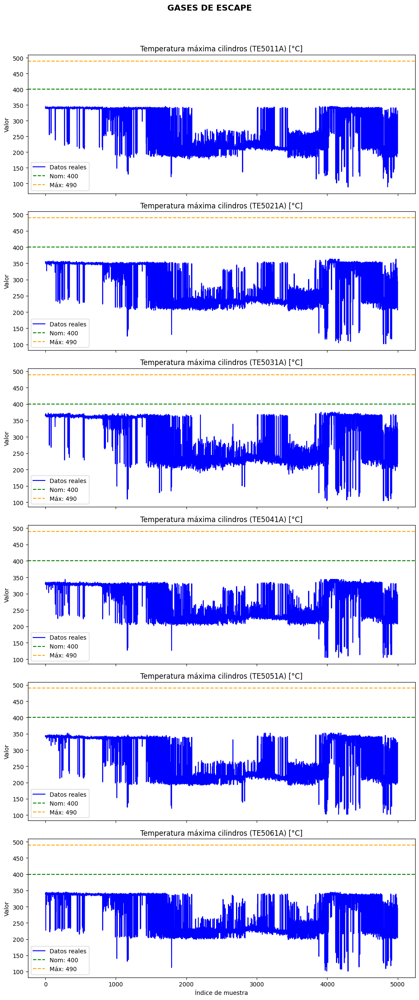

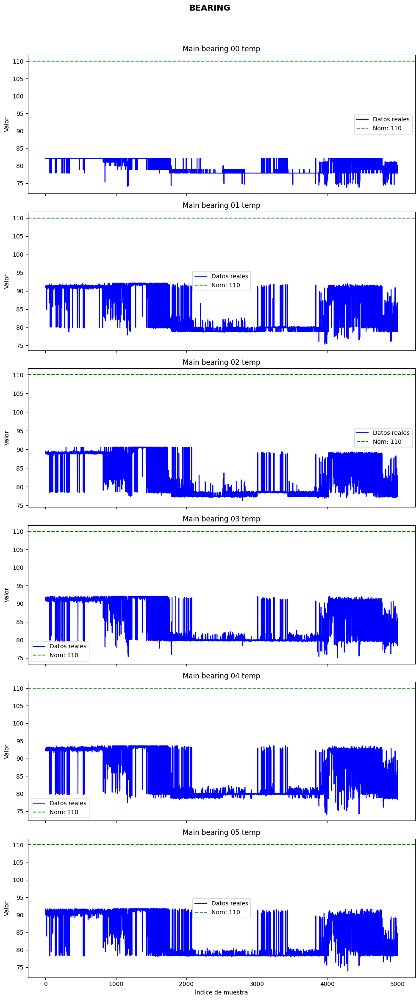

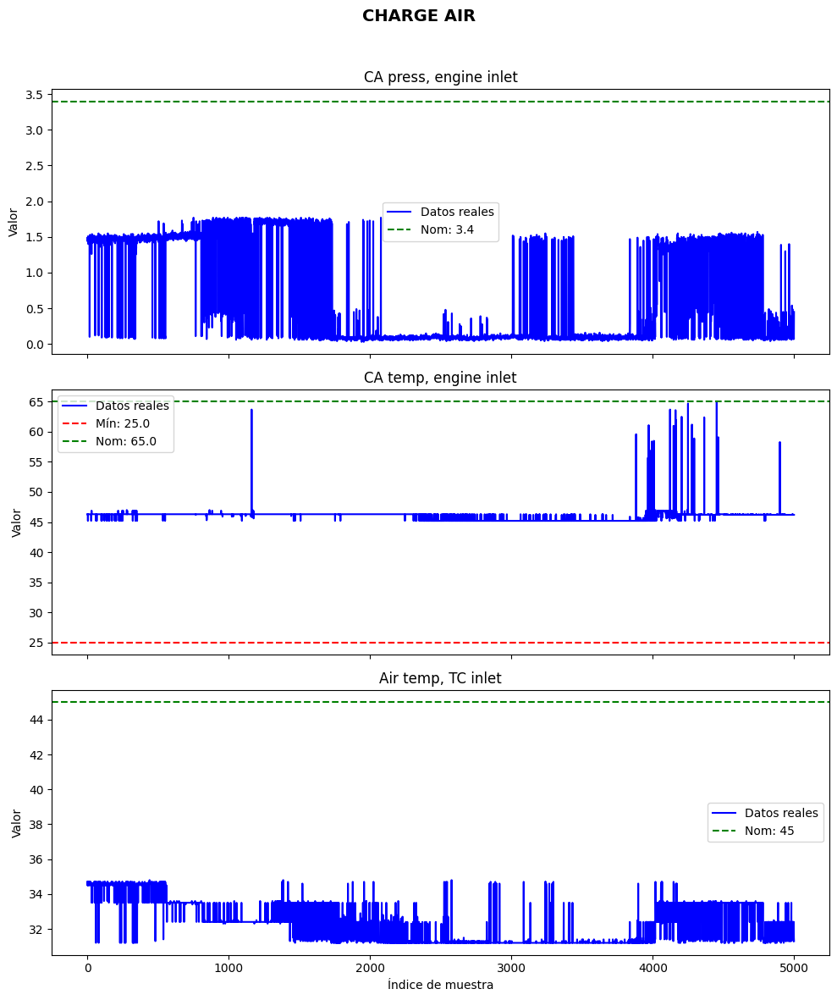

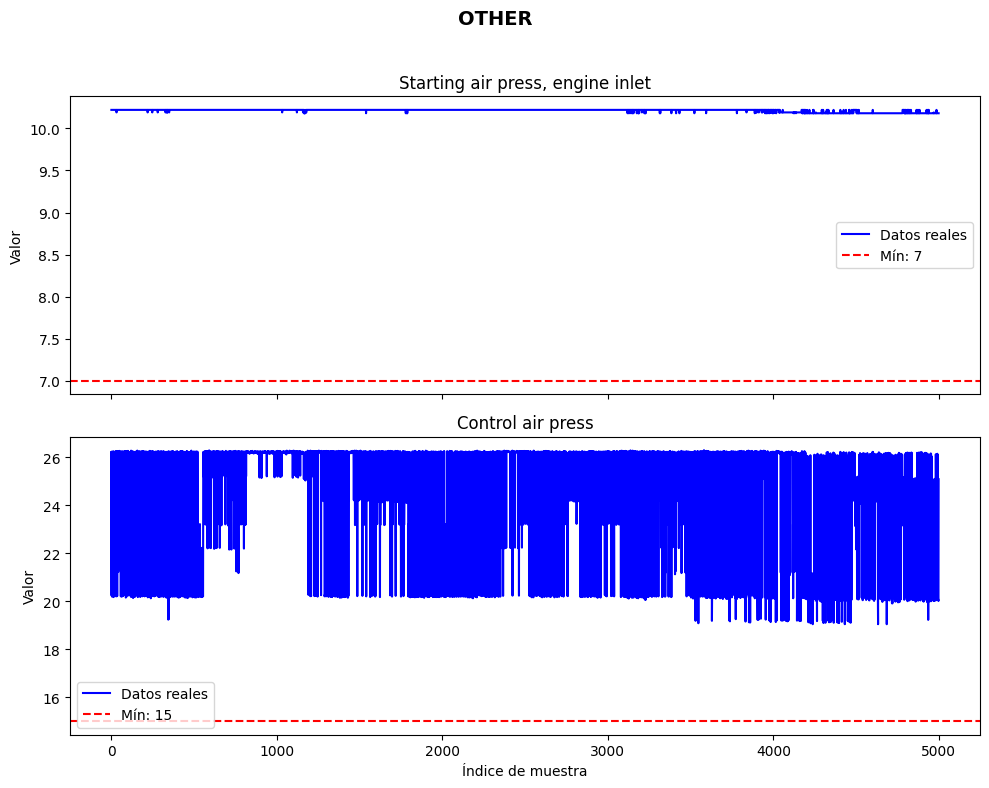

In [14]:
import pandas as pd
import matplotlib.pyplot as plt
import json

# Cargar CSV
df = pd.read_csv("synthetic_data_truncado_VAE_nuevos.csv")

# Crear copia sin valores vacíos
df2 = df.dropna()

print(f"Filas originales: {len(df)}, filas sin vacíos: {len(df2)}")

# Cargar JSON
with open("resultados.json", "r") as f:
    resultados = json.load(f)

# Diccionario subsistemas
subsistemas = {
    "FUEL SYSTEM": [
        "PT101",
        "TE101"
    ],
    "LUBRICACION": [
        "TE272",
        "PT201",
        "TE201",
        "PDT243",
        "TE202",
        "PT271"
    ],
    "COOLING": [
        "TE401",
        "TE402",
        "TE471"
    ],
    "GASES DE ESCAPE": [
        "TE5011A",
        "TE5021A",
        "TE5031A",
        "TE5041A",
        "TE5051A",
        "TE5061A"
    ],
    "BEARING": [
        "TE700",
        "TE701",
        "TE702",
        "TE703",
        "TE704",
        "TE705"
    ],
    "CHARGE AIR": [
        "PT601",
        "TE601",
        "TE600"
    ],
    "OTHER": [
        "PT301",
        "PT311"
    ]
}

# Graficar usando df2 en vez de df
for nombre_sistema, variables in subsistemas.items():
    fig, axs = plt.subplots(len(variables), 1, figsize=(10, 4 * len(variables)), sharex=True)
    if len(variables) == 1:
        axs = [axs]

    fig.suptitle(nombre_sistema, fontsize=14, fontweight="bold")

    for i, var in enumerate(variables):
        if var in df2.columns and var in resultados:
            axs[i].plot(df2.index, df2[var], label="Datos reales", color="blue")

            # Dibujar líneas solo si el valor no es None
            min_val = resultados[var].get("Valor mínimo")
            nom_val = resultados[var].get("Valor nominal")
            max_val = resultados[var].get("Valor máximo")

            if min_val is not None:
                axs[i].axhline(min_val, color="red", linestyle="--", label=f"Mín: {min_val}")
            if nom_val is not None:
                axs[i].axhline(nom_val, color="green", linestyle="--", label=f"Nom: {nom_val}")
            if max_val is not None:
                axs[i].axhline(max_val, color="orange", linestyle="--", label=f"Máx: {max_val}")

            axs[i].set_title(resultados[var]["Nombre"])
            axs[i].set_ylabel("Valor")
            axs[i].legend()
        else:
            axs[i].set_title(f"{var} (sin datos)")

    axs[-1].set_xlabel("Índice de muestra")
    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()



In [15]:
vectores_por_variable_vae_nuevos = {}
for var in df2.columns:
    vectores_por_variable_vae_nuevos[var] = df2[var].iloc[:4000].to_numpy()
    print(f"Longitud del vector de {var}: {len(vectores_por_variable_vae_nuevos[var])}")


Longitud del vector de TE401: 4000
Longitud del vector de TE402: 4000
Longitud del vector de TE471: 4000
Longitud del vector de PT101: 4000
Longitud del vector de TE101: 4000
Longitud del vector de PT201: 4000
Longitud del vector de TE201: 4000
Longitud del vector de TE202: 4000
Longitud del vector de TE272: 4000
Longitud del vector de PDT243: 4000
Longitud del vector de PT271: 4000
Longitud del vector de TE5011A: 4000
Longitud del vector de TE5021A: 4000
Longitud del vector de TE5031A: 4000
Longitud del vector de TE5041A: 4000
Longitud del vector de TE5051A: 4000
Longitud del vector de TE5061A: 4000
Longitud del vector de TE700: 4000
Longitud del vector de TE701: 4000
Longitud del vector de TE702: 4000
Longitud del vector de TE703: 4000
Longitud del vector de TE704: 4000
Longitud del vector de TE705: 4000
Longitud del vector de PT601: 4000
Longitud del vector de TE601: 4000
Longitud del vector de TE600: 4000
Longitud del vector de PT301: 4000
Longitud del vector de PT311: 4000
Longitu

In [ ]:
import numpy as np
import joblib
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dropout, RepeatVector, TimeDistributed, Dense
import tensorflow as tf
import os

# === Diccionario de subsistemas ===
subsistemas = {
    "FUEL SYSTEM": [
        "PT101",
        "TE101"
    ],
    "LUBRICACION": [
        "TE272",
        "PT201",
        "TE201",
        "PDT243",
        "TE202",
        "PT271"
    ],
    "COOLING": [
        "TE401",
        "TE402",
        "TE471"
    ],
    "GASES DE ESCAPE": [
        "TE5011A",
        "TE5021A",
        "TE5031A",
        "TE5041A",
        "TE5051A",
        "TE5061A"
    ],
    "BEARING": [
        "TE700",
        "TE701",
        "TE702",
        "TE703",
        "TE704",
        "TE705"
    ],
    "CHARGE AIR": [
        "PT601",
        "TE601",
        "TE600"
    ],
    "OTHER": [
        "PT301",
        "PT311"
    ]
}

# === Función para entrenar, evaluar y guardar modelo + scaler ===
def entrenar_y_evaluar_subsistema(nombre_subsistema, time_steps=30):
    variables_objetivo = subsistemas[nombre_subsistema]
    print(f"Entrenando modelo para: {nombre_subsistema}")
    print(f"Variables usadas: {variables_objetivo}")

    # === Extraer vectores para las variables del subsistema ===
    vector_multivariable_vae = np.stack(
        [vectores_por_variable_vae_nuevos[var] for var in variables_objetivo],
        axis=1
    )

    # === Escalado ===
    scaler_lstm_vae = MinMaxScaler()
    scaled_vector_vae = scaler_lstm_vae.fit_transform(vector_multivariable_vae)

    # === Crear secuencias ===
    def create_sequences(data, time_steps=30):
        sequences = []
        for i in range(len(data) - time_steps):
            sequences.append(data[i:i + time_steps])
        return np.array(sequences)

    X_lstm_vae = create_sequences(scaled_vector_vae, time_steps)
    np.random.seed(42)
    tf.random.set_seed(42)

    print(f"Forma de las secuencias: {X_lstm_vae.shape}")

    # === Modelo LSTM Autoencoder ===
    n_features = X_lstm_vae.shape[2]

    model_lstm_vae = Sequential([
        LSTM(128, activation='tanh', input_shape=(time_steps, n_features), return_sequences=False),
        Dropout(0.2),
        RepeatVector(time_steps),
        LSTM(128, activation='tanh', return_sequences=True),
        Dropout(0.2),
        TimeDistributed(Dense(n_features))
    ])

    model_lstm_vae.compile(optimizer='adam', loss='mse')

    # === Entrenamiento ===
    model_lstm_vae.fit(
        X_lstm_vae, X_lstm_vae,
        epochs=50,
        batch_size=32,
        validation_split=0.1,
        shuffle=False,
        verbose=1
    )

    # === Evaluación ===
    X_train_pred = model_lstm_vae.predict(X_lstm_vae)
    mae_train = np.mean(np.abs(X_train_pred - X_lstm_vae), axis=(1, 2))
    threshold = np.max(mae_train)
    print(f"Threshold para anomalías (máx. MAE entrenamiento): {threshold:.6f}")

    # === Guardar modelo y scaler ===
    carpeta_modelos = "modelos_guardados"
    os.makedirs(carpeta_modelos, exist_ok=True)

    nombre_limpio = nombre_subsistema.replace(" ", "_")
    ruta_modelo = os.path.join(carpeta_modelos, f"modelo_{nombre_limpio}.h5")
    ruta_scaler = os.path.join(carpeta_modelos, f"scaler_{nombre_limpio}.pkl")

    model_lstm_vae.save(ruta_modelo)
    joblib.dump(scaler_lstm_vae, ruta_scaler)

    print(f"✅ Modelo guardado en: {ruta_modelo}")
    print(f"✅ Scaler guardado en: {ruta_scaler}")

    return model_lstm_vae, scaler_lstm_vae, threshold

# === Ejemplo: entrenar, evaluar y guardar modelo para lubricación ===




In [ ]:
# Entrenar, evaluar y exportar un modelo por cada subsistema
modelos = {}
scalers = {}
umbrales = {}

for nombre_subsistema in subsistemas.keys():
    modelo, scaler, umbral = entrenar_y_evaluar_subsistema(nombre_subsistema)
    modelos[nombre_subsistema] = modelo
    scalers[nombre_subsistema] = scaler
    umbrales[nombre_subsistema] = umbral



Entrenando modelo para: FUEL SYSTEM
Variables usadas: ['PT101', 'TE101']
Forma de las secuencias: (3970, 30, 2)
Epoch 1/50


/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


112/112 ━━━━━━━━━━━━━━━━━━━━ 20s 109ms/step - loss: 0.0921 - val_loss: 0.0215
Epoch 2/50
112/112 ━━━━━━━━━━━━━━━━━━━━ 20s 108ms/step - loss: 0.0890 - val_loss: 0.0190
Epoch 3/50
112/112 ━━━━━━━━━━━━━━━━━━━━ 12s 107ms/step - loss: 0.0911 - val_loss: 0.0186
Epoch 4/50
112/112 ━━━━━━━━━━━━━━━━━━━━ 22s 117ms/step - loss: 0.0845 - val_loss: 0.0182
Epoch 5/50
112/112 ━━━━━━━━━━━━━━━━━━━━ 21s 121ms/step - loss: 0.0781 - val_loss: 0.0183
Epoch 6/50
112/112 ━━━━━━━━━━━━━━━━━━━━ 19s 109ms/step - loss: 0.0764 - val_loss: 0.0178
Epoch 7/50
112/112 ━━━━━━━━━━━━━━━━━━━━ 20s 108ms/step - loss: 0.0751 - val_loss: 0.0209
Epoch 8/50
112/112 ━━━━━━━━━━━━━━━━━━━━ 21s 109ms/step - loss: 0.0713 - val_loss: 0.0199
Epoch 9/50
112/112 ━━━━━━━━━━━━━━━━━━━━ 20s 108ms/step - loss: 0.0810 - val_loss: 0.0233
Epoch 10/50
112/112 ━━━━━━━━━━━━━━━━━━━━ 20s 107ms/step - loss: 0.0659 - val_loss: 0.0252
Epoch 11/50
112/112 ━━━━━━━━━━━━━━━━━━━━ 21s 112ms/step - loss: 0.0741 - val_loss: 0.0268
Epoch 12/50
112/112 ━━━━━━━━━━

Threshold para anomalías (máx. MAE entrenamiento): 0.299256
✅ Modelo guardado en: modelos_guardados/modelo_FUEL_SYSTEM.h5
✅ Scaler guardado en: modelos_guardados/scaler_FUEL_SYSTEM.pkl
Entrenando modelo para: LUBRICACION
Variables usadas: ['TE272', 'PT201', 'TE201', 'PDT243', 'TE202', 'PT271']
Forma de las secuencias: (3970, 30, 6)


/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


...

Epoch 1/50
112/112 ━━━━━━━━━━━━━━━━━━━━ 19s 106ms/step - loss: 0.0767 - val_loss: 0.0081
Epoch 2/50
112/112 ━━━━━━━━━━━━━━━━━━━━ 11s 100ms/step - loss: 0.0521 - val_loss: 0.0077
Epoch 3/50
112/112 ━━━━━━━━━━━━━━━━━━━━ 20s 94ms/step - loss: 0.0551 - val_loss: 0.0077
Epoch 4/50
112/112 ━━━━━━━━━━━━━━━━━━━━ 22s 104ms/step - loss: 0.0491 - val_loss: 0.0078
Epoch 5/50
112/112 ━━━━━━━━━━━━━━━━━━━━ 21s 113ms/step - loss: 0.0492 - val_loss: 0.0078
Epoch 6/50
112/112 ━━━━━━━━━━━━━━━━━━━━ 19s 98ms/step - loss: 0.0514 - val_loss: 0.0079
Epoch 7/50
112/112 ━━━━━━━━━━━━━━━━━━━━ 21s 103ms/step - loss: 0.0544 - val_loss: 0.0079
Epoch 8/50
112/112 ━━━━━━━━━━━━━━━━━━━━ 11s 99ms/step - loss: 0.0573 - val_loss: 0.0078
Epoch 9/50
112/112 ━━━━━━━━━━━━━━━━━━━━ 11s 100ms/step - loss: 0.0560 - val_loss: 0.0079
Epoch 10/50
112/112 ━━━━━━━━━━━━━━━━━━━━ 11s 101ms/step - loss: 0.0546 - val_loss: 0.0077
Epoch 11/50
112/112 ━━━━━━━━━━━━━━━━━━━━ 21s 107ms/step - loss: 0.0507 - val_loss: 0.0079
Epoch 12/50
112/112 ━━

Threshold para anomalías (máx. MAE entrenamiento): 0.237697
✅ Modelo guardado en: modelos_guardados/modelo_CHARGE_AIR.h5
✅ Scaler guardado en: modelos_guardados/scaler_CHARGE_AIR.pkl
Entrenando modelo para: OTHER
Variables usadas: ['PT301', 'PT311']
Forma de las secuencias: (3970, 30, 2)


/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/50
112/112 ━━━━━━━━━━━━━━━━━━━━ 16s 106ms/step - loss: 0.1535 - val_loss: 0.0947
Epoch 2/50
112/112 ━━━━━━━━━━━━━━━━━━━━ 20s 98ms/step - loss: 0.0710 - val_loss: 0.0875
Epoch 3/50
112/112 ━━━━━━━━━━━━━━━━━━━━ 12s 108ms/step - loss: 0.0676 - val_loss: 0.0850
Epoch 4/50
112/112 ━━━━━━━━━━━━━━━━━━━━ 11s 98ms/step - loss: 0.0683 - val_loss: 0.0842
Epoch 5/50
112/112 ━━━━━━━━━━━━━━━━━━━━ 10s 90ms/step - loss: 0.0676 - val_loss: 0.0837
Epoch 6/50
112/112 ━━━━━━━━━━━━━━━━━━━━ 11s 94ms/step - loss: 0.0669 - val_loss: 0.0836
Epoch 7/50
112/112 ━━━━━━━━━━━━━━━━━━━━ 11s 98ms/step - loss: 0.0662 - val_loss: 0.0835
Epoch 8/50
112/112 ━━━━━━━━━━━━━━━━━━━━ 21s 98ms/step - loss: 0.0650 - val_loss: 0.0835
Epoch 9/50
112/112 ━━━━━━━━━━━━━━━━━━━━ 20s 99ms/step - loss: 0.0640 - val_loss: 0.0834
Epoch 10/50
112/112 ━━━━━━━━━━━━━━━━━━━━ 20s 97ms/step - loss: 0.0626 - val_loss: 0.0833
Epoch 11/50
112/112 ━━━━━━━━━━━━━━━━━━━━ 22s 109ms/step - loss: 0.0611 - val_loss: 0.0832
Epoch 12/50
112/112 ━━━━━━━

Threshold para anomalías (máx. MAE entrenamiento): 0.361803
✅ Modelo guardado en: modelos_guardados/modelo_OTHER.h5
✅ Scaler guardado en: modelos_guardados/scaler_OTHER.pkl
